# Building a Surrogate Model for the Williams-Otto Reactor

Goal: 
- Build a Surrogate Model which is faster to solve than the original first principles model
- ML Model is supposed to be used to predict values over the whole horizon

Model Architectures:
- Multistep Model
- Recursively used Model trained on 1 step error
- Recursively used Model trained on simulation error
- how many lags necessary

Numerical Tricks:
- train difference to simple model (ala UDE) or persistence
- read paper again for more ideas!!!

Evaluation Metric:
- Model Error
- Prediction time for whole horizon vs first principles model
- ...


## Setup

In [30]:
# Imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import time
from IPython.display import display
from dataclasses import dataclass

import warnings
warnings.filterwarnings('ignore')

import keras
from keras import Sequential
from keras.layers import (Dense, Activation, Dropout, LSTM, GRU, Conv1D, MaxPooling1D,
                          MaxPooling3D, Flatten, SimpleRNN, ConvLSTM2D, RepeatVector,
                          TimeDistributed, Input)
from keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import r2_score
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split

from scipy.stats import qmc
from scipy.integrate import solve_ivp

In [31]:
# Problem Definition

# How to pick DT
# from simulation.estimate_time_constants 
# fastest tau: 0.138 min (8.3 s)
# slowest tau: 7.20 min
# longest settling time (t95): 21.4 min

# Horizon should be longer than the longest settling time, so > 21.4 min so settled state is visible for mpc
# we pick H = 20 steps, not too many so not too computationally expensive
# so DT = 21.4 / 20 = 1.07 min ~ 1 min
# this means that the model will not be aware of the fastes dynamics

@dataclass(frozen=True)
class Config:
    DT: float = 1                                   # Sampling Time [min]
    H: int = 20                                     # Horizon [steps]
    NY: int = 6                                     # Output-Dimension
    NU: int = 2                                     # Input-Dimension
    SEED: int = 7

    QB_bounds: tuple = (180.0, 360.0)               # dm3/min
    Tr_bounds: tuple = (75 + 273.15, 100 + 273.15)  # K (75-100 degC)

    names_y: tuple = ("cA", "cB", "cC", "cP", "cE", "cG")
    names_U: tuple = ("QB", "Tr")

CFG = Config()

In [32]:
# Set random seed for reproducibility
np.random.seed(CFG.SEED)
keras.utils.set_random_seed(CFG.SEED)

## Data Generation

In [33]:
# First principles Model
params = {
    "k10": 9.9594e6,      # dm3/(mol*min)
    "k20": 8.66124e9,     # dm3/(mol*min)
    "k30": 9.9594e6,      # dm3/(mol*min)
    "E1": 6666.7,          # K
    "E2": 8333.3,          # K
    "E3": 11111.0,         # K
    "cA0": 10.0,            # mol/dm3
    "cB0": 10.0,            # mol/dm3
    "V": 2105.0,             # dm3
    "QA": 112.35,           # dm3/min
}

def wo_reactor_odes(t, c, u):
    """
    ODE system of the Williams-Otto CSTR.

    Inputs:
        t : float, current time
        c : array of 6 floats [cA, cB, cC, cP, cE, cG] in mol/dm3
        u : (QB, Tr)
            QB : float, flow rate of B in dm3/min
            Tr : float, reactor temperature in K

    Output:
        list of 6 floats [dcA, dcB, dcC, dcP, dcE, dcG] in mol/(dm3*min)
    """
    cA, cB, cC, cP, cE, cG = c
    QB, Tr = u

    QA = params["QA"]
    Qr = QA + QB
    V = params["V"]

    k1 = params["k10"] * np.exp(-params["E1"] / Tr)
    k2 = params["k20"] * np.exp(-params["E2"] / Tr)
    k3 = params["k30"] * np.exp(-params["E3"] / Tr)

    r1 = k1 * cA * cB
    r2 = k2 * cB * cC
    r3 = k3 * cC * cP

    dcA = (QA * params["cA0"] - Qr * cA) / V - r1
    dcB = (QB * params["cB0"] - Qr * cB) / V - r1 - r2
    dcC = (-Qr * cC) / V + r1 - r2 - r3
    dcP = (-Qr * cP) / V + r2 - r3
    dcE = (-Qr * cE) / V + r2
    dcG = (-Qr * cG) / V + r3

    return [dcA, dcB, dcC, dcP, dcE, dcG]


# Integrates ODE system for 1 step
def step(y0, u, dt):
    sol = solve_ivp(lambda t, c: wo_reactor_odes(t, c, u), (0, dt), y0,method="BDF", rtol=1e-8, atol=1e-10)
    return sol.y[:, -1]


In [34]:
def draw_dwell_times(n_steps, hold_range, rng, log_uniform=True):
    h_min, h_max = hold_range
    dwell, total = [], 0
    while total < n_steps:
        if log_uniform:
            h = int(round(np.exp(np.random.uniform(np.log(h_min), np.log(h_max))))) # the same amount over all orders of magnitude
        else:
            h = int(rng.integers(h_min, h_max, endpoint=True))
        dwell.append(h)
        total += h
    return np.array(dwell)


def make_aprbs(n_steps, hold_range, input_dim, input_max, input_min, dwelltime_same, rng, log_uniform=True):
    if dwelltime_same==True:                                            # inputs with same dwell times, sampled on same hypercube
        dwell = draw_dwell_times(n_steps, hold_range, rng, log_uniform)
        unit = qmc.LatinHypercube(d=input_dim, seed=rng).random(len(dwell))
        amp = qmc.scale(unit, input_min, input_max)
        U = np.repeat(amp, dwell, axis=0)[:n_steps]
    else:                                                               # pick inputs with different dwell times, different hypercubes
        cols = []
        for i in range(input_dim):
            dwell = draw_dwell_times(n_steps, hold_range, rng, log_uniform)
            unit = qmc.LatinHypercube(d=1, seed=rng).random(len(dwell))
            amp = qmc.scale(unit, input_min[i], input_max[i])
            cols.append(np.repeat(amp, dwell)[:n_steps]) # repeat each amplitude dwell times amount and cut off aftter n_steps is reached
        U =  np.column_stack(cols)
    return U

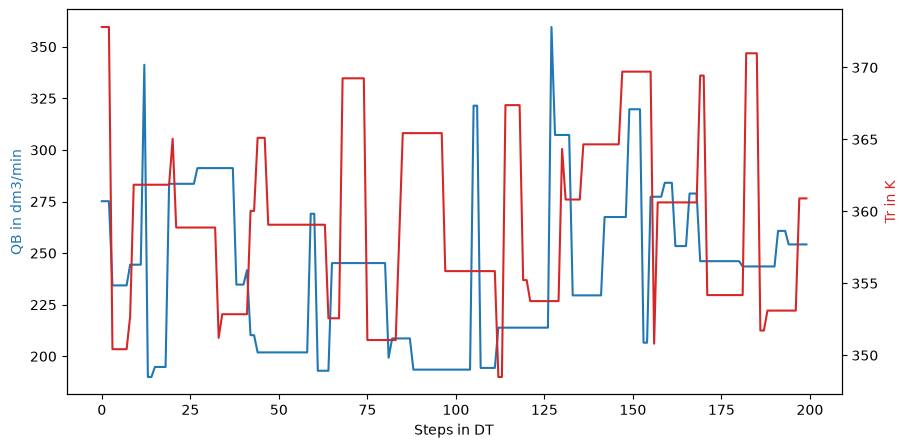

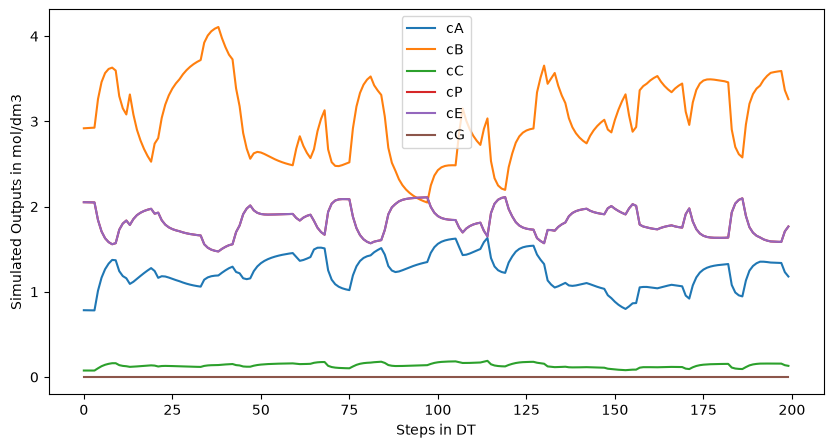

In [35]:
# Hyperparameters for data generation
N_steps=2000 + 2*CFG.H              # how many steps are simulated
hold_range=(1,CFG.H)                # how long one input is held constant
dwelltime_same=False                # decides if the both inputs have the same dwell times or different ones
log_uniform = True
rng = np.random.default_rng(CFG.SEED)
U_lo, U_hi = [CFG.QB_bounds[0],CFG.Tr_bounds[0]], [CFG.QB_bounds[1],CFG.Tr_bounds[1]]


# Generate APRBS inputs
U = make_aprbs(n_steps=N_steps, hold_range=hold_range, input_dim=CFG.NU, input_max=U_hi, input_min=U_lo, 
               dwelltime_same=dwelltime_same, rng=rng, log_uniform=log_uniform)

# Simulate system for generated inputs
y0 = [10,10,0,0,0,0]
y = [y0]
for i in range(N_steps):
    y.append(step(y0,U[i,:],CFG.DT))
    y0 = y[-1]
y = np.array(y)

# throw the first H=20 steps away cause it shows dynamics that startup dynamics (not in normal operation)
U = U[2*CFG.H:,:]
y = y[2*CFG.H:,:]
N_steps = len(U)


# Plot inputs and outputs for example steps n_plot
n_plot=200
fig, ax1 = plt.subplots(figsize=(10,5))
ax1.plot(range(n_plot),U[:n_plot,0],color="tab:blue")
ax1.set_xlabel('Steps in DT'), 
ax1.set_ylabel('QB in dm3/min',color="tab:blue"),
ax2 = ax1.twinx()
ax2.plot(range(n_plot),U[:n_plot,1], color="tab:red")
ax2.set_ylabel("Tr in K", color="tab:red")

plt.figure(figsize=(10,5))
plt.plot(range(n_plot),y[:n_plot,:])
plt.xlabel('Steps in DT'), plt.ylabel('Simulated Outputs in mol/dm3'), plt.legend(CFG.names_y)
plt.tight_layout
plt.show()

In [36]:
# Measure solve time first principle model
n_rep = 10                                                      # average over n_rep runs
sel = np.random.choice(len(U)-CFG.H, size=n_rep, replace=False)
inference_times = []

for i in range(n_rep):
    o = [y[sel[i],:]]
    start_time = time.perf_counter()
    for j in range(CFG.H):
        o.append(step(o[-1],U[sel[i]+j,:],CFG.DT))
    inference_times.append(time.perf_counter() - start_time)
avg_time_fpm = np.mean(inference_times)*1000 # in ms
print(avg_time_fpm)

40.88837919989601


## Data Exploration

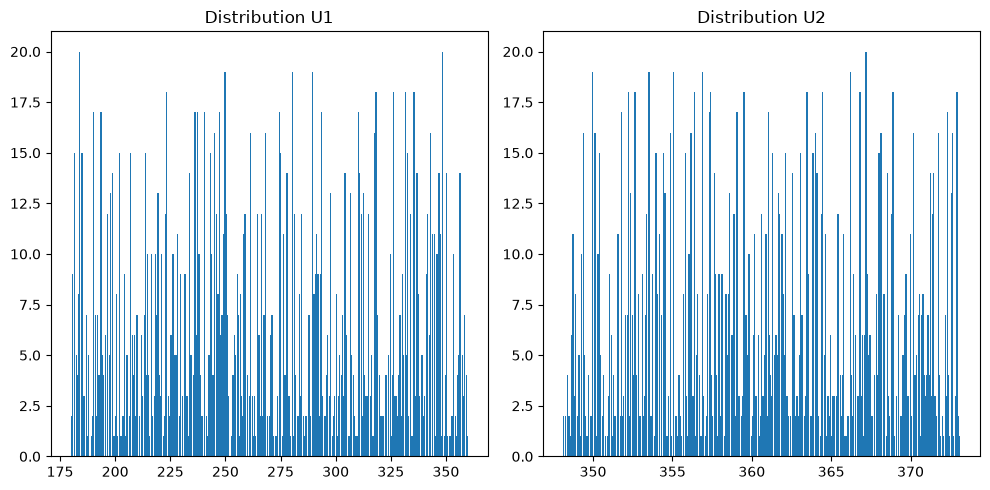

Time Steps =  2000
unique values:
U1:  320
U2:  315
avg / min / max dwell time steps:
U1: 6.25  /  1  /  20
U2: 6.35  /  1  /  20
min / max values:
U1:  180.06 359.58  (bounds= (180.0, 360.0) )
U2:  348.15 373.08  (bounds= (348.15, 373.15) )


In [37]:
# Look at inputs

vals_U1_unique, counts_U1_unique = np.unique(U[:,0], return_counts=True)
vals_U2_unique, counts_U2_unique = np.unique(U[:,1], return_counts=True)

# the y axis of the hist shows how long each input was held for
fig,axes = plt.subplots(1,2,figsize=(10,5))
axes[0].bar(vals_U1_unique,counts_U1_unique, width=(CFG.QB_bounds[1]-CFG.QB_bounds[0])/len(vals_U1_unique))
axes[0].set_title('Distribution U1')
axes[1].bar(vals_U2_unique,counts_U2_unique, width=(CFG.Tr_bounds[1]-CFG.Tr_bounds[0])/len(vals_U2_unique))
axes[1].set_title('Distribution U2')
fig.tight_layout()
plt.show()

# some stats
print("Time Steps = ",N_steps)
print("unique values:")
print("U1: ",len(vals_U1_unique))
print("U2: ",len(vals_U2_unique))
print("avg / min / max dwell time steps:")
print("U1:",round(N_steps/len(vals_U1_unique),2)," / ", np.min(counts_U1_unique)," / ", np.max(counts_U1_unique))
print("U2:",round(N_steps/len(vals_U2_unique),2)," / ", np.min(counts_U2_unique)," / ", np.max(counts_U2_unique))
print("min / max values:")
print("U1: ",round(np.min(U[:,0]),2), round(np.max(U[:,0]),2)," (bounds=",CFG.QB_bounds,")")
print("U2: ",round(np.min(U[:,1]),2), round(np.max(U[:,1]),2)," (bounds=",CFG.Tr_bounds,")")


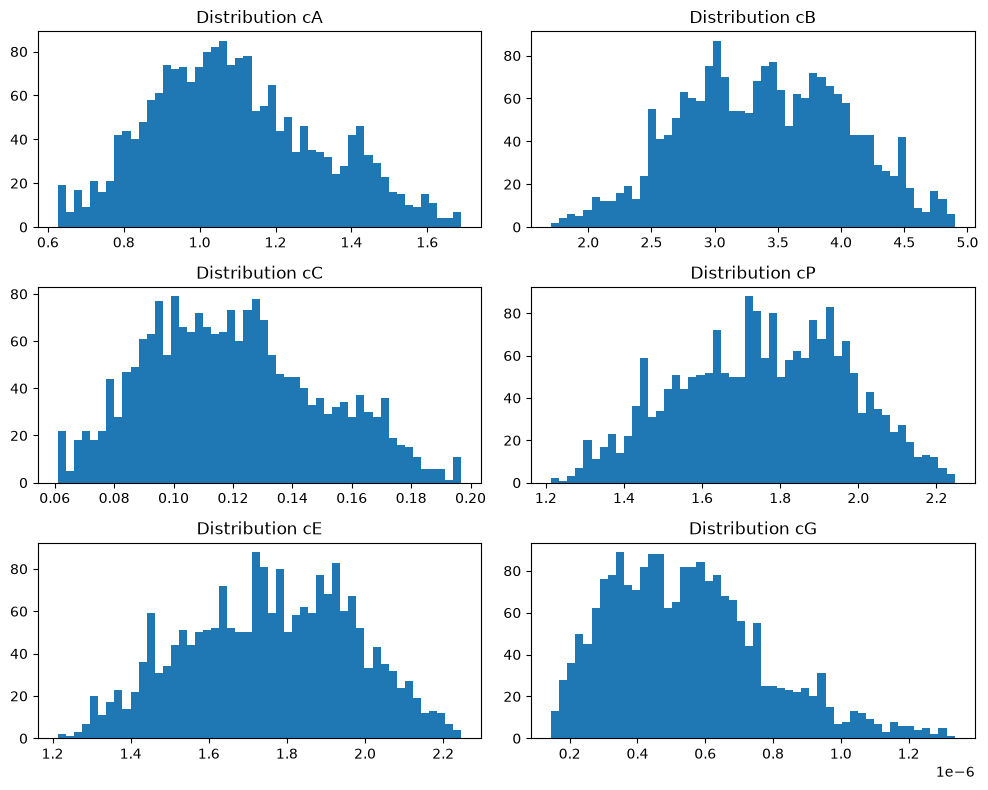

In [38]:
# Look at Outputs
fig,axes = plt.subplots(3,2,figsize=(10,8))
axes[0,0].hist(y[:,0],bins=50), axes[0,0].set_title("Distribution cA")
axes[0,1].hist(y[:,1],bins=50), axes[0,1].set_title("Distribution cB")
axes[1,0].hist(y[:,2],bins=50), axes[1,0].set_title("Distribution cC")
axes[1,1].hist(y[:,3],bins=50), axes[1,1].set_title("Distribution cP")
axes[2,0].hist(y[:,4],bins=50), axes[2,0].set_title("Distribution cE")
axes[2,1].hist(y[:,5],bins=50), axes[2,1].set_title("Distribution cG")
plt.tight_layout()
plt.show()

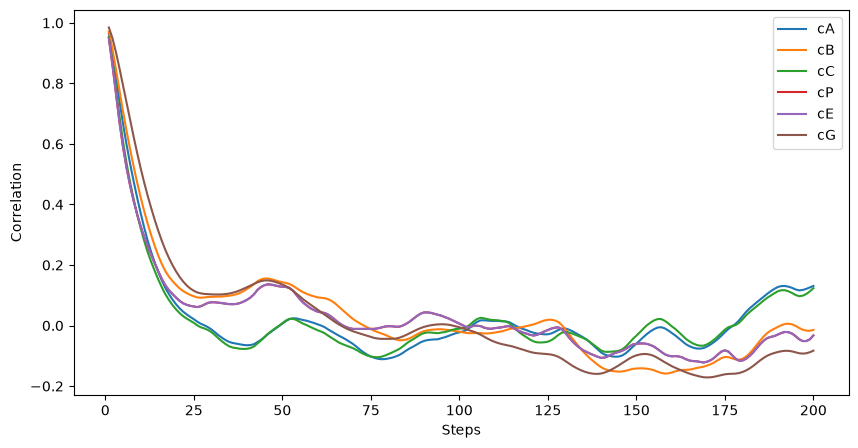

In [39]:
# Correlation between past and future values
n_past = 200
n_var = CFG.NY
r = [[] for _ in range(n_var)]

for j in range(n_var):
    x = y[:, j]
    for i in range(1, n_past + 1):
        r[j].append(np.corrcoef(x[:-i], x[i:])[0, 1])

r = np.array(r)

plt.figure(figsize=(10, 5))
plt.plot(range(1, n_past + 1), r.T)
plt.xlabel("Steps")
plt.ylabel("Correlation")
plt.legend(CFG.names_y)
plt.show()

# the closer the time steps the higher the correlation, which is expected.

The Questions is how many lags (past time steps) are necessary as input for the model to perform well.
Since the the whole state is measured it could be argued that only the last step is necessary, cause the state per definition carries all the information about the model. This should be varified through tests.

## Data Preperation

U: (2000, 2)
y: (2001, 6)
Utrain:  (1400, 2)
ytrain:  (1400, 6)
Uval:  (400, 2)
yval:  (400, 6)
Utest:  (200, 2)
ytest:  (201, 6)


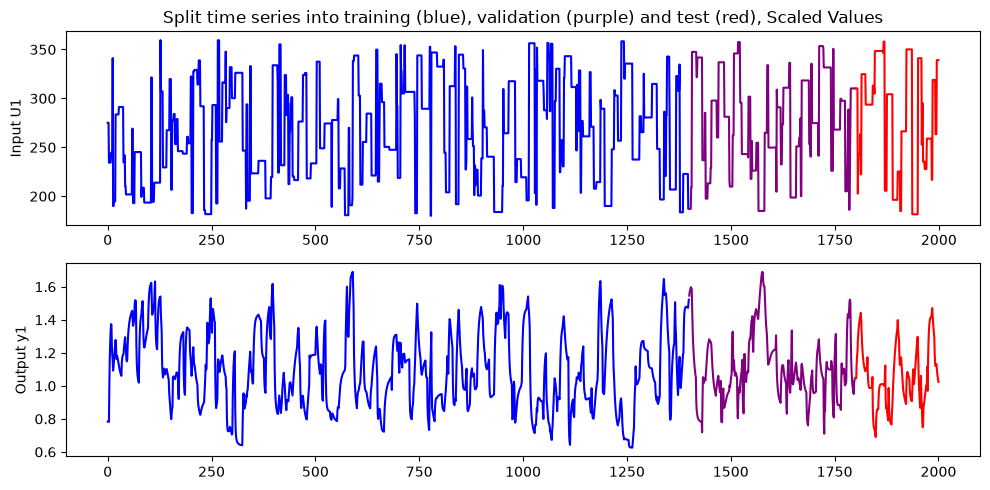

In [40]:
# Split into train, validation and test sets
train_size = int(N_steps * 0.7)
val_size = int(N_steps * 0.2)
Utrain, Uval, Utest = U[0:train_size,:], U[train_size:train_size+val_size,:], U[train_size+val_size:,:]
ytrain, yval, ytest = y[0:train_size,:], y[train_size:train_size+val_size,:], y[train_size+val_size:,:]

# Print shapes
print("U:", U.shape) 
print("y:", y.shape)
print("Utrain: ",Utrain.shape)
print("ytrain: ",ytrain.shape)
print("Uval: ",Uval.shape)
print("yval: ",yval.shape)
print("Utest: ",Utest.shape)
print("ytest: ",ytest.shape)

# Plot splitting
fig,axes = plt.subplots(2,1,figsize=(10,5))
axes[0].plot(range(train_size),Utrain[:,0],'b')
axes[0].plot(range(train_size,train_size+val_size),Uval[:,0],color='purple')
axes[0].plot(range(train_size+val_size,train_size+val_size+len(Utest)),Utest[:,0],'r')
axes[0].set_ylabel("Input U1")
axes[0].set_title("Split time series into training (blue), validation (purple) and test (red), Scaled Values")
axes[1].plot(range(train_size),ytrain[:,0],'b')
axes[1].plot(range(train_size,train_size+val_size),yval[:,0],color='purple')
axes[1].plot(range(train_size+val_size,train_size+val_size+len(ytest)),ytest[:,0],'r')
axes[1].set_ylabel("Output y1")
plt.tight_layout()
plt.show()

X: (1385, 96)
W: (1385, 30)


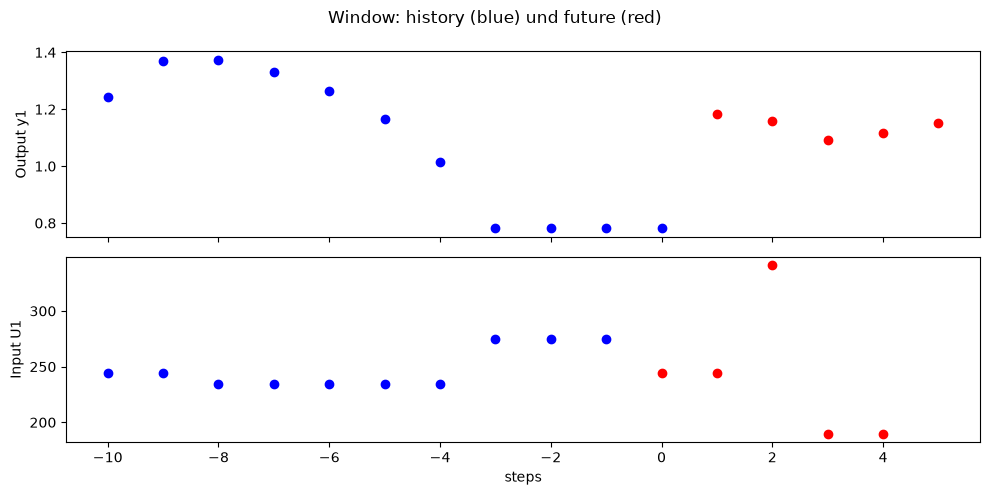

In [41]:
def make_windows(y, U, look_back=0, look_ahead=1, multistep=False):
    # look_back=0 means only current state, look_ahead=1 means 1 step ahead predicted
    N = len(U)
    n_y, n_u = CFG.NY, CFG.NU
    t = np.arange(look_back, N - look_ahead)
    y_hist = [y[t - j] for j in range(look_back + 1)]
    u_past = [U[t - j] for j in range(1, look_back + 1)]
    u_fut  = [U[t + k] for k in range(look_ahead)]
    X = np.hstack(y_hist + u_past + u_fut)

    if multistep:
        W = np.hstack([y[t + k] for k in range(1, look_ahead + 1)])   # multistep: (B, look_ahead*n_y)
    else:
        W = y[t + look_ahead]                                         # 1 step: (B, n_y)

    a = (look_back + 1) * n_y
    b = a + look_back * n_u

    def decode_window(X=None, W=None):
        out = {}
        if X is not None:
            X = np.atleast_2d(X)
            B = len(X)
            out["y_hist"] = X[:, :a].reshape(B, look_back + 1, n_y)   # y(t), y(t-1), ...
            out["u_past"] = X[:, a:b].reshape(B, look_back, n_u)      # u(t-1), u(t-2), ...
            out["u_future"]  = X[:, b:].reshape(B, look_ahead, n_u)   # u(t), u(t+1), ...
        if W is not None:
            W = np.atleast_2d(W)
            B = len(W)
            if multistep:
                out["y_future"] = W.reshape(B, look_ahead, n_y)       # # y(t+1), y(t+2), ...
            else:
                out["y_future"] = W.reshape(B, n_y)
        return out

    return X, W, decode_window


# Example
tryX, tryW, decode = make_windows(ytrain,Utrain,look_back=10,look_ahead=5,multistep=True)

print("X:", tryX.shape)
print("W:", tryW.shape)

out = decode(tryX,tryW)
fig,axes = plt.subplots(2,1,figsize=(10,5), sharex=True)
fig.suptitle("Window: history (blue) und future (red)")
axes[0].plot(range(-10,1),out["y_hist"][0,:,0],'bo')
axes[0].plot(range(1,6),out["y_future"][0,:,0],'ro')
axes[0].set_ylabel("Output y1")
axes[1].plot(range(-10,0),out["u_past"][0,:,0],'bo')
axes[1].plot(range(0,5),out["u_future"][0,:,0],'ro')
axes[1].set_ylabel("Input U1")
axes[-1].set_xlabel("steps")

fig.tight_layout()
plt.show()

In [42]:
# Make Pipeline
class WindowPipeline:
    def __init__(self, look_back=0, look_ahead=1, multistep=False):
        self.lb, self.la, self.ms = look_back, look_ahead, multistep
        self.sc_y, self.sc_u = StandardScaler(), StandardScaler()

    def fit(self, y, U):                            # fir with training data
        self.sc_y.fit(y); self.sc_u.fit(U)
        return self

    def transform(self, y, U):                      # Scales data and makes window in 1 step
        X, W, self.decode_window = make_windows(self.sc_y.transform(y), self.sc_u.transform(U), self.lb, self.la, self.ms)
        return X, W

    def inverse_W(self, W):                         # invertes scaling of W and window in 1 step
        n_y = self.sc_y.n_features_in_
        W3 = self.decode_window(W=W)["y_future"]           # multistep: (B, la, n_y) , normal: (B, n_y)
        return self.sc_y.inverse_transform(W3.reshape(-1, CFG.NY)).reshape(W3.shape) # reshape to (B*la, n_y) for scaler afterwards back again

### Export training data for the MATLAB linear baseline

Run this cell after generating and splitting the reactor data. Then run the updated **n4sid1.m** in MATLAB. It exports numeric matrices and preprocessing parameters; it performs no validation, plotting, or ML evaluation.

MATLAB retains the original `train.csv` fit and optionally fits a second model using **exactly this notebook's training samples**. Re-export and refit whenever the generated training data change. Neither notebook validation nor test samples are exported for fitting. Return to the comparison cells after the ML training cells to run all evaluation in Python.

**Portable paths:** both the notebook and MATLAB script start from the current working directory and search upward for the project data/layout. From a project subdirectory, they use the detected project root. In a standalone folder they use that folder. Launch both tools in the same project/workspace; the detected location is printed. All data and report paths are constructed relative to it. The original N4SID data generator and its train/validation files remain part of the workflow.

In [43]:
# Run after the data split, before fitting the MATLAB baseline.
from pathlib import Path
import json

def find_project_root(start=None):
    # Start from the user's working directory, including when the notebook
    # kernel is launched in src/evaluation or another project subdirectory.
    working_dir = Path.cwd().resolve() if start is None else Path(start).resolve()
    for candidate in (working_dir, *working_dir.parents):
        has_project_layout = (candidate / 'src').is_dir() and (candidate / 'data').is_dir()
        has_bridge_data = any((candidate / 'data' / 'n4sid' / name).is_file()
                              for name in ('train.csv', 'notebook_train.csv'))
        if has_project_layout or has_bridge_data:
            return candidate
    # Standalone notebook: use the current directory as its workspace.
    return working_dir


PROJECT_ROOT = find_project_root()
N4SID_DIR = PROJECT_ROOT / 'data' / 'n4sid'
COMPARISON_DIR = N4SID_DIR / 'notebook_evaluation'
N4SID_DIR.mkdir(parents=True, exist_ok=True)
print('Project/workspace directory:', PROJECT_ROOT)

# y[k] is observed BEFORE applying U[k] over the next sampling interval.
# Export ONLY this notebook's training partition, never validation/test rows.
bridge_U = np.asarray(Utrain, dtype=float)
bridge_Y = np.asarray(ytrain, dtype=float)[:len(bridge_U)]
if bridge_Y.shape != (len(bridge_U), CFG.NY):
    raise ValueError('Training input/output alignment is invalid.')
bridge_frame = pd.DataFrame(bridge_Y, columns=CFG.names_y)
bridge_frame.insert(0, 'time_min', np.arange(len(bridge_U)) * CFG.DT)
for j, name in enumerate(CFG.names_U):
    bridge_frame[name] = bridge_U[:, j]
bridge_file = N4SID_DIR / 'notebook_train.csv'
bridge_frame.to_csv(bridge_file, index=False)
print(f'Exported training-only data: {bridge_file}')
print('Next: run the updated n4sid1.m in MATLAB, then return to the comparison cells below.')
print('MATLAB fits the original-data model and, when available, a notebook-training-data model.')


Project/workspace directory: /Users/nilsbulitta/Documents/GitHub/data_science_project_26fall
Exported training-only data: /Users/nilsbulitta/Documents/GitHub/data_science_project_26fall/data/n4sid/notebook_train.csv
Next: run the updated n4sid1.m in MATLAB, then return to the comparison cells below.
MATLAB fits the original-data model and, when available, a notebook-training-data model.


## Evaluation Function

In [44]:
# Comparison dataframe
df_models = pd.DataFrame(columns=['model_name', 'direct_or_recursive', 'look_back', 'look_ahead', 'training_time_in_ms', 'inference_time', 'train_rmse', 'test_rmse','train_r2','test_r2'])
df_models.loc[0, ["model_name", "inference_time"]] = ["First principles", avg_time_fpm]
df_models

,model_name,direct_or_recursive,look_back,look_ahead,training_time_in_ms,inference_time,train_rmse,test_rmse,train_r2,test_r2
0,First principles,NaN,NaN,NaN,NaN,40.888379,NaN,NaN,NaN,NaN


In [45]:
# Saving trained Models
model_bank = {}

In [46]:
def rollout_batch(model, pipe, y, U, starts, H):
    # all start points at once; loop only over the horizon h
    lb = pipe.lb
    ys_all = pipe.sc_y.transform(y)                               # (N+1, n_y) scaled
    us_all = pipe.sc_u.transform(U)                               # (N, n_u)   scaled

    # ys[j] holds y(t0 - lb + j) for all starts, shape (S, n_y); grows by one prediction per step
    ys = [ys_all[starts - lb + j] for j in range(lb + 1)]
    preds = []
    for h in range(H):
        y_in = np.hstack(ys[::-1][:lb + 1])                       # y(t), y(t-1), ...  
        u_in = [us_all[starts + h - j] for j in range(1, lb + 1)] # u(t-1), ..., u(t-lb); empty list for lb=0
        u_now = us_all[starts + h]                                # u(t)
        x = np.hstack([y_in] + u_in + [u_now])                    # same order as make_windows, (S, n_features)
        y_next = (model(x, training=False).numpy() if len(x) <= 256    # small batch: direct call
                  else model.predict(x, batch_size=4096, verbose=0))   # (S, n_y), one call for all starts
        ys.append(y_next)                                         # prediction becomes the newest y
        preds.append(y_next)
    P = np.stack(preds, axis=1)                                   # (S, H, n_y), scaled
    return pipe.sc_y.inverse_transform(P.reshape(-1, P.shape[-1])).reshape(P.shape)

def predict_horizon(model, pipe, y, U, mode="direct", H=None):
    lb = pipe.lb
    if mode == "direct":
        X, W = pipe.transform(y, U)
        pred = pipe.inverse_W(model.predict(X, verbose=0))
        true = pipe.inverse_W(W)
        if pred.ndim == 2:                                  # adjust shape for 1 step model: (B, n_y) -> (B, 1, n_y)
            pred, true = pred[:, None, :], true[:, None, :]
        starts = np.arange(lb, lb + len(pred))
    elif mode == "recursive":
        n_max = min(len(U), len(y) - 1)
        starts = np.arange(lb, n_max - H + 1, 1)
        pred = rollout_batch(model, pipe, y, U, starts, H)            # (S, H, n_y)
        true = y[starts[:, None] + 1 + np.arange(H)]                  # (S, H, n_y): y(t0+1) ... y(t0+H)
    else:
        raise ValueError(f"unknown mode: {mode}")
    return pred, true, starts                               # (S, H, n_y), (S, H, n_y), (S,)

def persistence_from_starts(y, starts, H):                  # y(t+k) = y(t)
    return np.repeat(y[starts][:, None, :], H, axis=1)      # (S, H, n_y)

def report_scores(pipe, name, true, pred, names, disp=True):            # true, pred are physical, (B, H, n_y)
    s = pipe.sc_y.scale_
    err_sc = (pred - true) / s                                          # error in std units
    rmse_overall = np.sqrt(np.mean(err_sc ** 2))                        # all steps, all variables, scalar
    rmse_per_var = np.sqrt(np.mean(err_sc ** 2, axis=(0, 1)))           # per variable over all steps, (n_y,)
    rmse_per_step = np.sqrt(np.mean(err_sc ** 2, axis=(0, 2)))          # per step over all variables, (H,)
    r2 = r2_score(true.reshape(-1, len(s)), pred.reshape(-1, len(s)),
                  multioutput="raw_values")                             # per variable, (n_y,)

    if disp:
        print(name)
        df_var = pd.DataFrame({"RMSE (scaled)": rmse_per_var, "R2": r2}, index=names)
        df_var.loc["all"] = [rmse_overall, r2.mean()]                   # last column: overall values
        print(df_var.T.round(2).to_string())                            # Transpose df
        print()
    return rmse_per_var, r2, rmse_per_step, rmse_overall                # all scaled values

In [47]:
def evaluate(model, pipe, mode, H, Utrain, ytrain, Utest, ytest, history, training_time, df_models, Name):
    # all X and y are given unscaled

    # Plot training history
    plt.figure(figsize=(20, 5))
    plt.plot(history.history['loss'], color='blue')
    plt.plot(history.history['val_loss'], color='red')
    plt.title('Training History', fontsize=20)
    plt.ylabel('loss')
    plt.xlabel('epoch')
    plt.legend(['Train', 'Validation'], loc='upper right', fontsize=14)
    plt.show()

    # Model Predictions
    Ytrain_pred, Ytrain_true, Ytrain_starts = predict_horizon(model, pipe, ytrain, Utrain, mode, H) # pred and true always 3 dim: [S,H,ny]
    Ytest_pred, Ytest_true, Ytest_starts = predict_horizon(model, pipe, ytest, Utest, mode, H)
    Ytrain_pers = persistence_from_starts(ytrain, Ytrain_starts, H)
    Ytest_pers = persistence_from_starts(ytest, Ytest_starts, H)

    # Score model and persistence
    res = {}
    for split, true, pred, pers in [("Train", Ytrain_true, Ytrain_pred, Ytrain_pers),
                                    ("Test",  Ytest_true,  Ytest_pred,  Ytest_pers)]:
        res[split] = report_scores(pipe, split + "Data", true, pred, CFG.names_y,disp=True)
        res[split + " pers"] = report_scores(pipe, "", true, pers, CFG.names_y,disp=False)
    trainScore, trainR2 = res["Train"][3], np.mean(res["Train"][1])
    testScore, testR2 = res["Test"][3], np.mean(res["Test"][1])

    # Plot predictions for Test Data, 1 and H-step prediction
    ks = sorted({1, H})
    fig, axes = plt.subplots(len(CFG.names_y), 1, sharex=True, figsize=(20, 2.5 * len(CFG.names_y)))
    axes = np.atleast_1d(axes)
    for j, ax in enumerate(axes):
        ax.plot(np.arange(len(ytest)), ytest[:, j], color="black", lw=1.5, label="Truth")
        for k in ks:
            ax.plot(Ytest_starts + k, Ytest_pred[:, k - 1, j], "--", label=f"Prediction +{k}")
        ax.set_ylabel(CFG.names_y[j])
    axes[0].legend(loc="upper right")
    axes[-1].set_xlabel("Steps")
    fig.suptitle(f"{Name} ({mode}): Prediction on Test Data")
    plt.tight_layout(); plt.show()

    # Plot prediction errors: scaled RMSE
    plt.figure(figsize=(10, 4))
    steps = np.arange(1, H + 1)
    for split in ["Train", "Test"]:
        plt.plot(steps, res[split][2], "o-", label=f"{split} Modell")
        plt.plot(steps, res[split + " pers"][2], "x--", label=f"{split} Persistence")
    plt.xlabel("Step"); plt.ylabel("RMSE (scaled)")
    plt.title(f"{Name} ({mode}): Error over Horizon")
    plt.legend(); plt.show()

    # Measure inference times
    Xtest, _ = pipe.transform(ytest, Utest)
    n_rep = 10                                                      # average over n_rep runs
    sel = np.random.choice(len(Ytest_starts), size=n_rep, replace=False)

    if mode == "recursive":
        lb = pipe.lb
        def one_prediction(i):
            return rollout_batch(model, pipe, ytest, Utest, Ytest_starts[i:i + 1], H)
    else:
        def one_prediction(i):
            return model(Xtest[i:i + 1], training=False)            # one call, all steps

    one_prediction(sel[0])                                          # warm up, doesnt count
    inference_times = []
    for i in sel:
        start_time = time.perf_counter()
        one_prediction(i)
        inference_times.append(time.perf_counter() - start_time)
    avg_time = np.mean(inference_times)*1000 # in ms

    # Save to Data Frame
    look_back, look_ahead = pipe.lb, pipe.la
    cols = ['direct_or_recursive', 'look_back', 'look_ahead', 'training_time_in_ms', 'inference_time',
            'train_rmse', 'test_rmse', 'train_r2', 'test_r2']
    vals = [mode,look_back, look_ahead, training_time, avg_time, trainScore, testScore, trainR2, testR2]
    if (df_models['model_name'] == Name).any():                     # if name exists already just update otherwise make new row
        df_models.loc[df_models['model_name'] == Name, cols] = vals
    else:
        new_row = pd.DataFrame([[Name] + vals], columns=['model_name'] + cols)
        df_models = pd.concat([df_models, new_row], ignore_index=True)
    display(df_models.infer_objects().round(2))
    return df_models

In [48]:
# Test the Pipeline and Evaluation Function on MLP
trypipe = WindowPipeline(look_back=0, look_ahead=CFG.H, multistep=True)
trypipe.fit(ytrain,Utrain)
tryXtrain,tryWtrain = trypipe.transform(ytrain,Utrain)
tryXval,tryWval = trypipe.transform(yval,Uval)

keras.utils.clear_session()

# Build Model
model = Sequential([
    Input(shape=(tryXtrain.shape[1],)),     # Input is vector length for 1 feature sample
    Dense(32,activation='tanh'),
    Dense(16,activation='tanh'),
    Dense(8, activation='tanh'),
    Dense(tryWtrain.shape[1])               # Output is vector length for 1 target sample
])

# Compile model
model.compile(loss='mean_squared_error', optimizer='adam',metrics=[keras.metrics.R2Score()])

# Train model
t0 = time.perf_counter()
history = model.fit(tryXtrain, tryWtrain,
                    epochs=32, batch_size=128,
                    validation_data=(tryXval,tryWval),
                    verbose=1)

end_time = time.time()
training_time = time.perf_counter() - t0

Epoch 1/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.9974 - r2_score: 0.0029 - val_loss: 0.9812 - val_r2_score: -0.0784
Epoch 2/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9430 - r2_score: 0.0573 - val_loss: 0.9381 - val_r2_score: -0.0304
Epoch 3/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8926 - r2_score: 0.1076 - val_loss: 0.8891 - val_r2_score: 0.0227
Epoch 4/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8380 - r2_score: 0.1622 - val_loss: 0.8348 - val_r2_score: 0.0804
Epoch 5/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7806 - r2_score: 0.2195 - val_loss: 0.7792 - val_r2_score: 0.1387
Epoch 6/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7248 - r2_score: 0.2752 - val_loss: 0.7269 - val_r2_score: 0.1933
Epoch 7/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6742 - r2_score: 0.3256 - val_loss: 0.6809 - val_r2_score: 0.2415
Epoch 8/32
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6307 - r2_score: 0.3691 - val_loss: 0.6422 - val_r2_sco

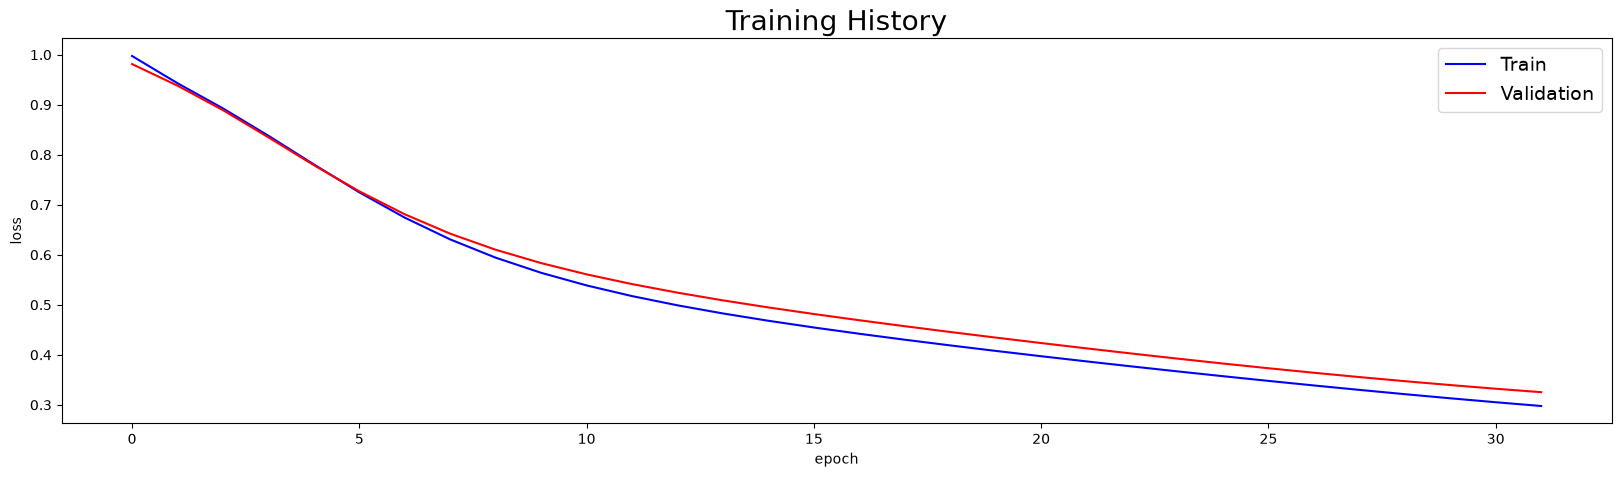

TrainData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.60  0.48  0.62  0.52  0.53  0.48  0.54
R2             0.64  0.77  0.61  0.73  0.72  0.77  0.71

TestData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.57  0.75  0.59  0.73  0.75  0.75  0.69
R2             0.44  0.68  0.47  0.72  0.70  0.71  0.62



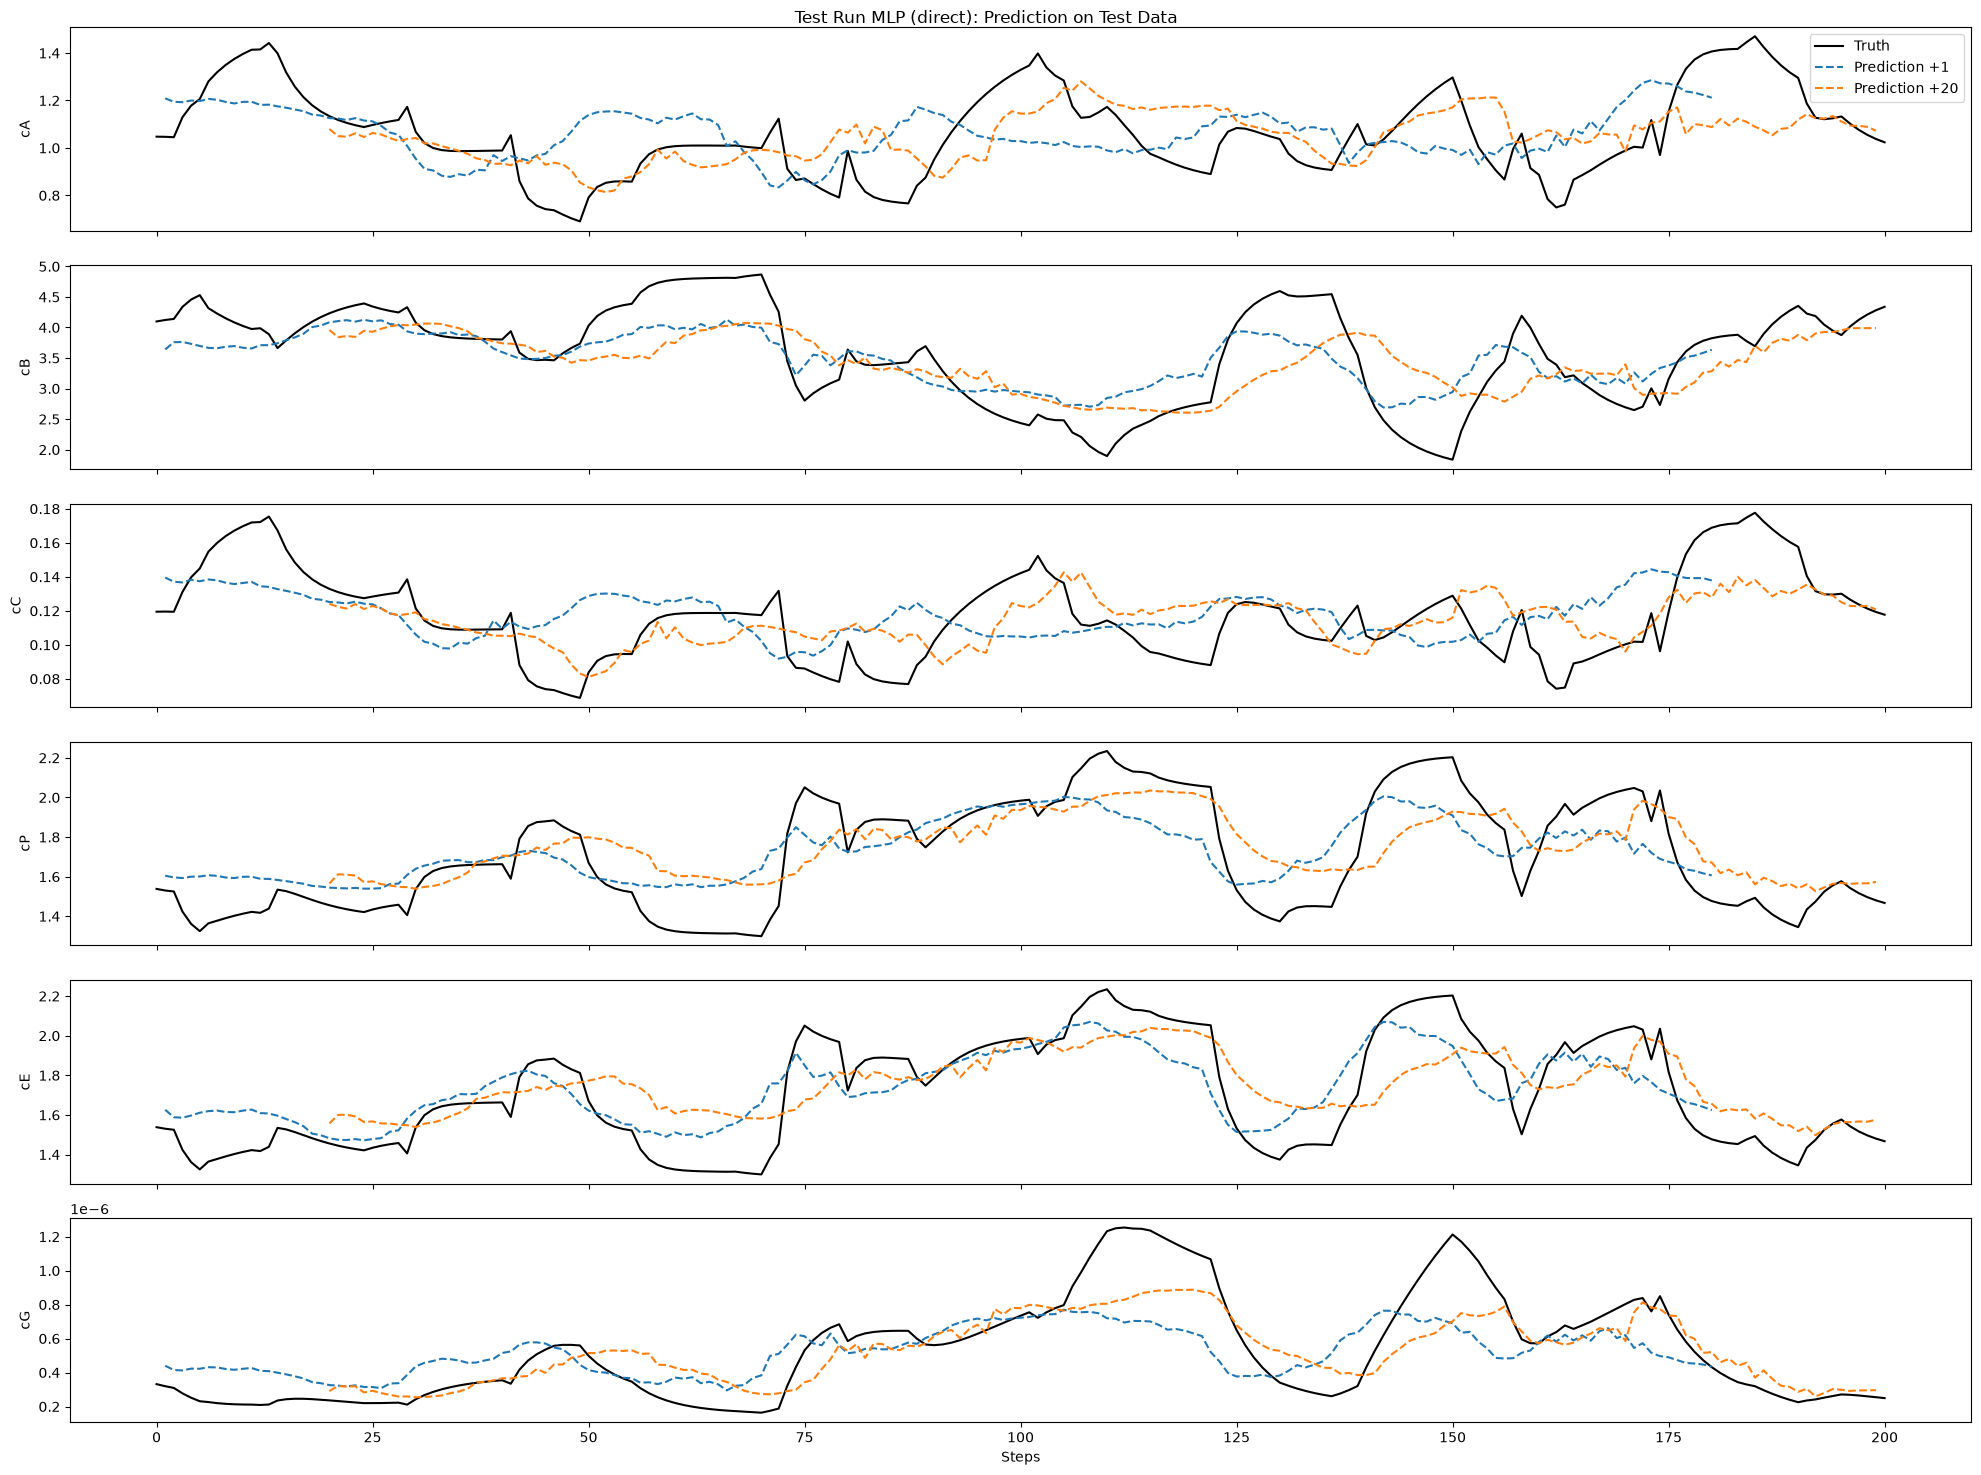

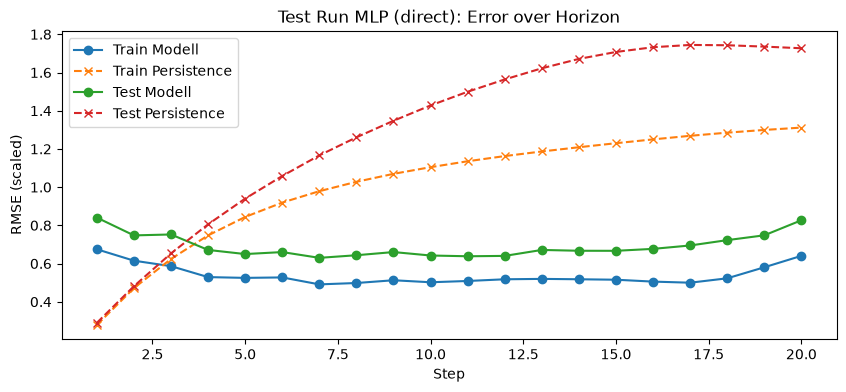

,model_name,direct_or_recursive,look_back,look_ahead,training_time_in_ms,inference_time,train_rmse,test_rmse,train_r2,test_r2
0,First principles,NaN,NaN,NaN,NaN,40.89,NaN,NaN,NaN,NaN
1,Test Run MLP,direct,0.0,20.0,3.21,3.25,0.54,0.69,0.71,0.62


In [49]:
model_bank["Test Run MLP"] = (model, trypipe, "direct")
df_models = evaluate(model, trypipe, "direct", CFG.H, Utrain, ytrain, Utest, ytest, history, training_time, df_models, "Test Run MLP")

## Model Explorations

#### 1. Multistep Model

Epoch 1/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 1.0114 - r2_score: -0.0112 - val_loss: 0.9808 - val_r2_score: -0.0821 - learning_rate: 0.0010
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.9281 - r2_score: 0.0719 - val_loss: 0.8970 - val_r2_score: 0.0079 - learning_rate: 0.0010
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.8424 - r2_score: 0.1574 - val_loss: 0.8091 - val_r2_score: 0.1018 - learning_rate: 0.0010
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7544 - r2_score: 0.2452 - val_loss: 0.7228 - val_r2_score: 0.1940 - learning_rate: 0.0010
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.6725 - r2_score: 0.3270 - val_loss: 0.6486 - val_r2_score: 0.2741 - learning_rate: 0.0010
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.6044 - r2_score: 0.3951 - val_loss: 0.5921 - val_r2_score: 0.3367 - learning_rate: 0.0010
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5510 - r2_score: 0.4485 - val_

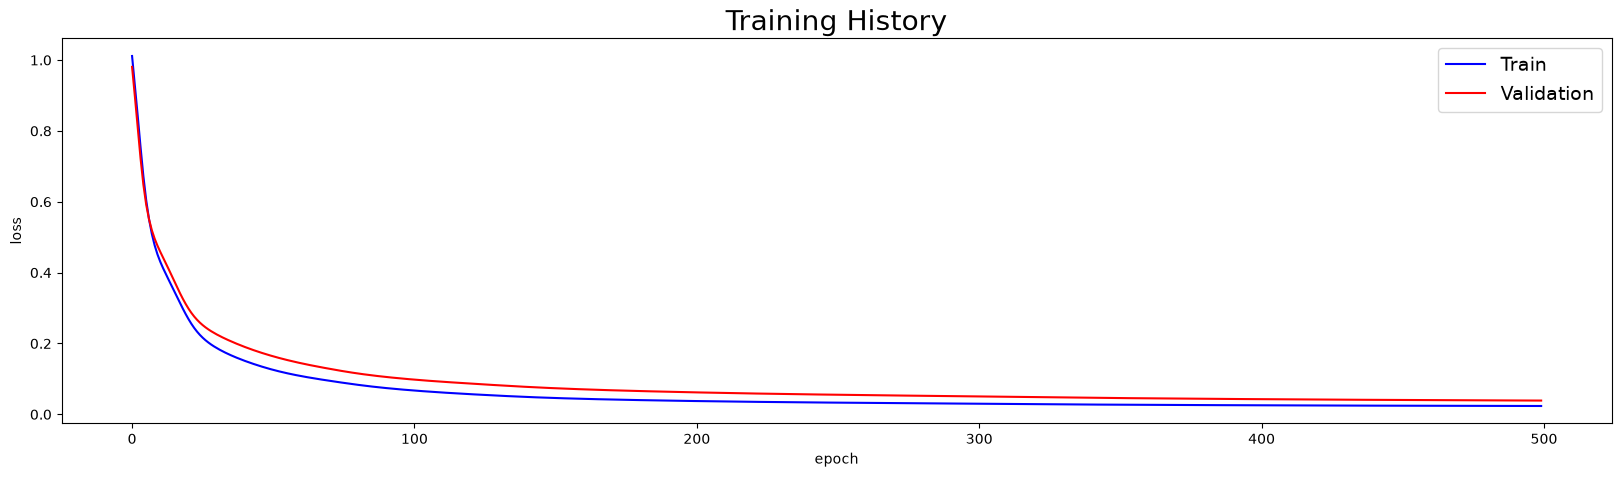

TrainData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.14  0.12  0.16  0.15  0.15  0.19  0.15
R2             0.98  0.98  0.98  0.98  0.98  0.97  0.98

TestData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.17  0.18  0.18  0.21  0.21  0.28  0.21
R2             0.95  0.98  0.95  0.98  0.98  0.96  0.97



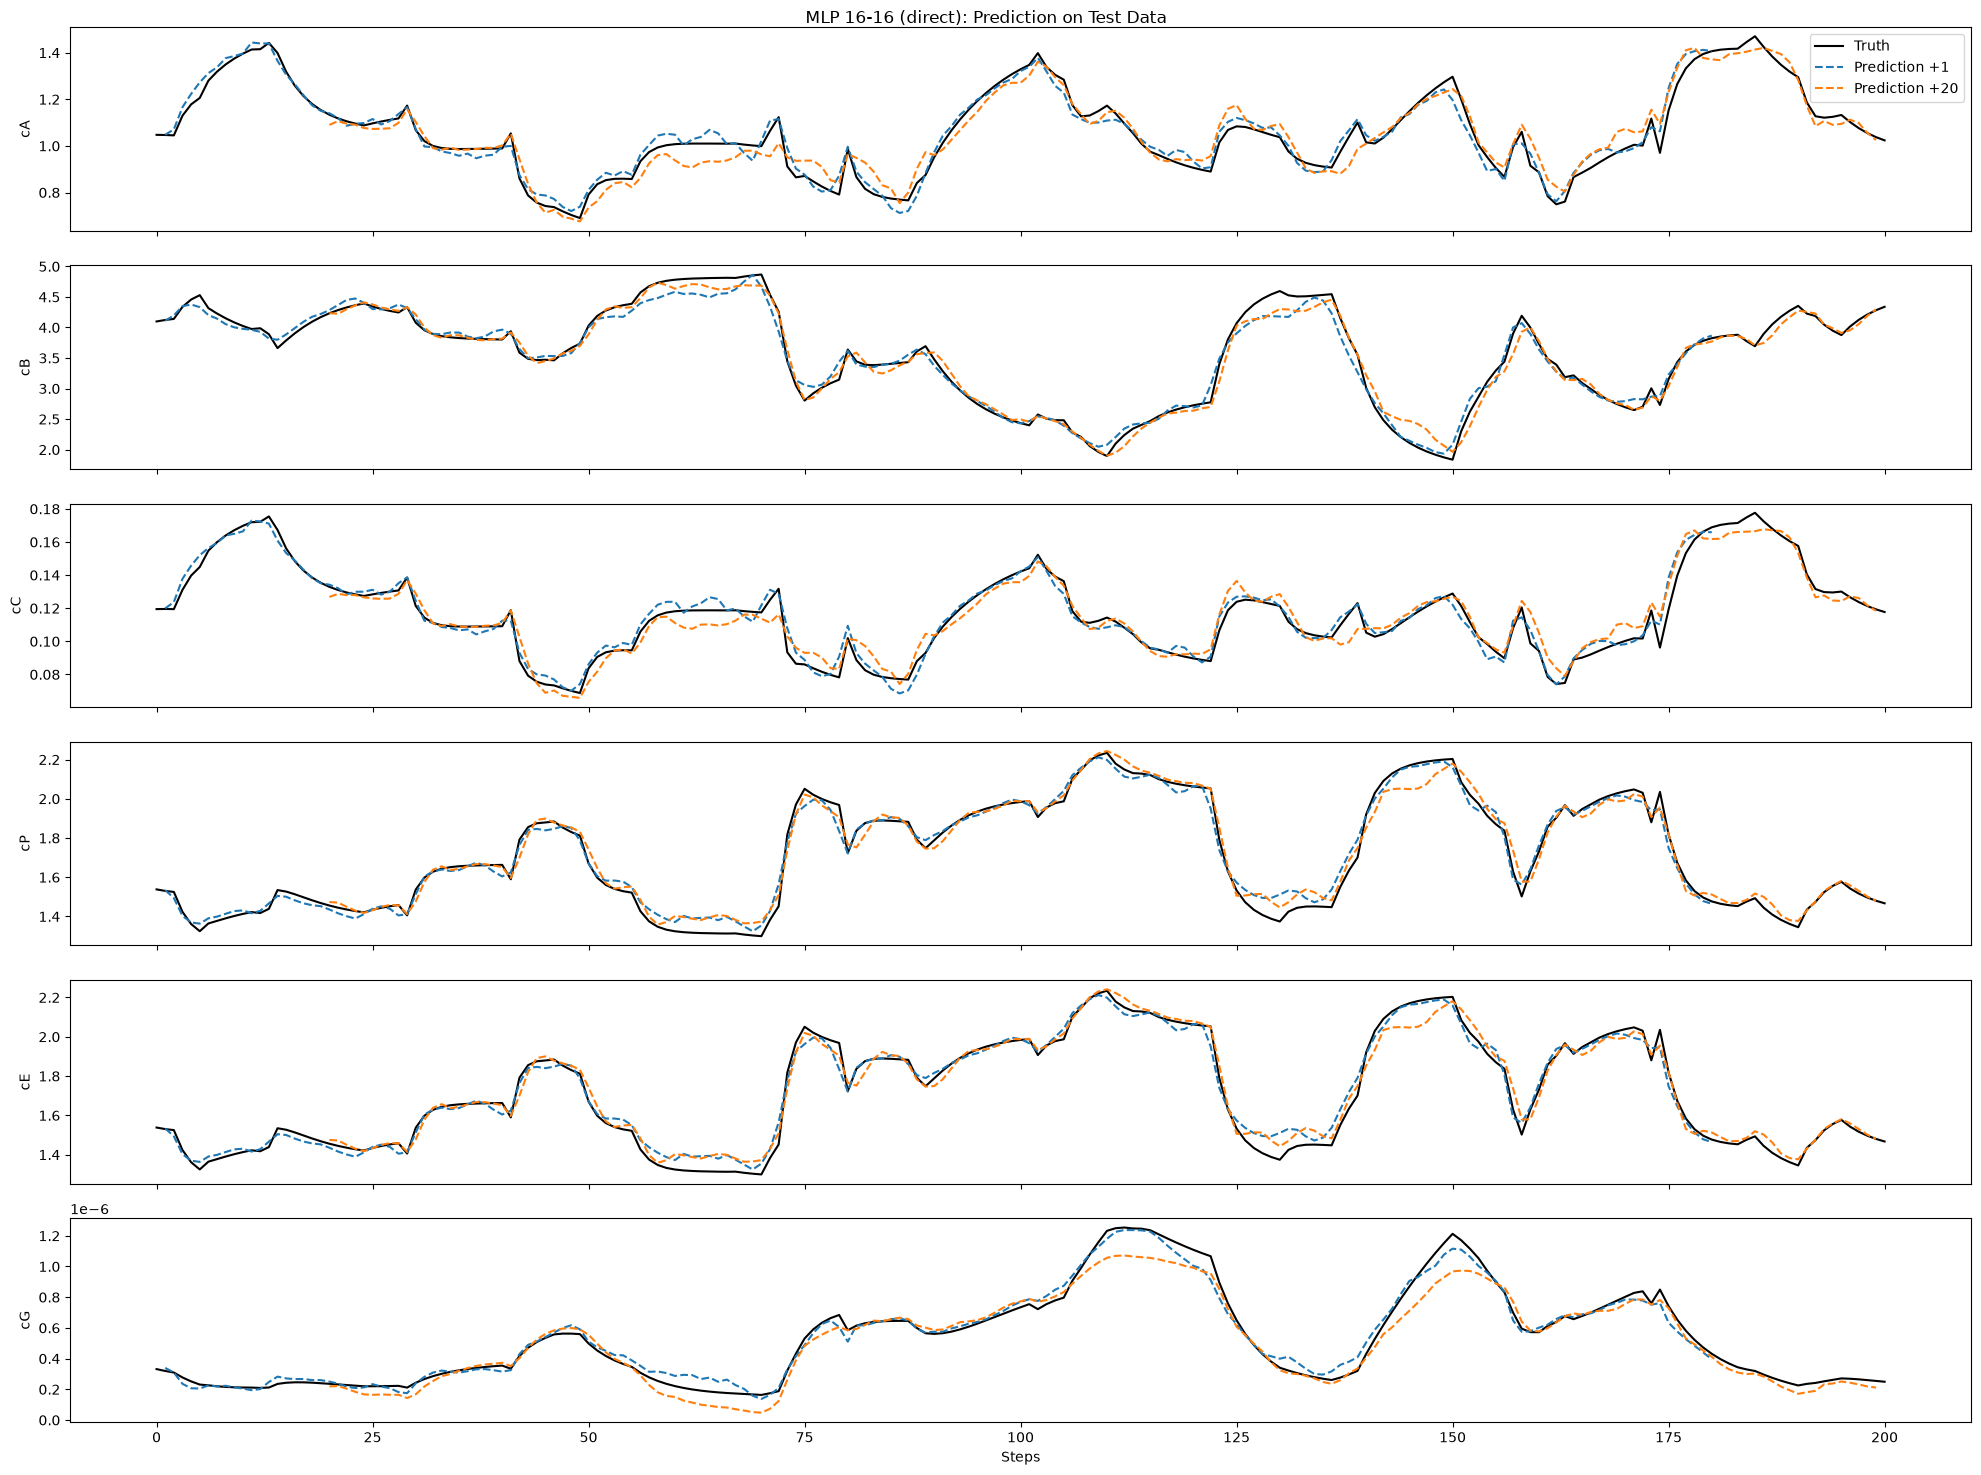

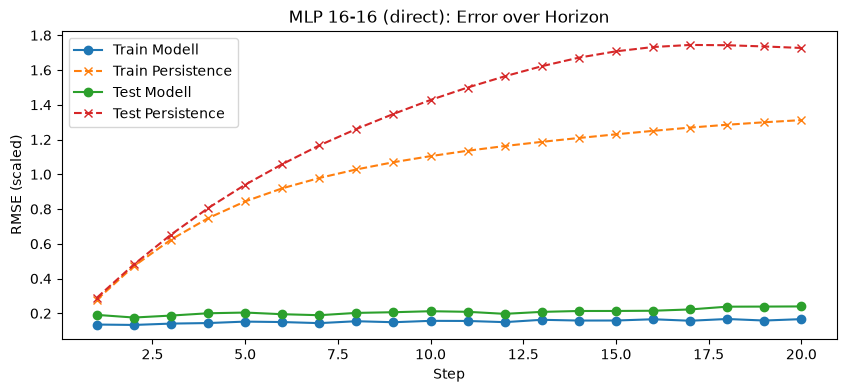

,model_name,direct_or_recursive,look_back,look_ahead,training_time_in_ms,inference_time,train_rmse,test_rmse,train_r2,test_r2
0,First principles,NaN,NaN,NaN,NaN,40.89,NaN,NaN,NaN,NaN
1,Test Run MLP,direct,0.0,20.0,3.21,3.25,0.54,0.69,0.71,0.62
2,MLP 16-16,direct,0.0,20.0,31.29,2.37,0.15,0.21,0.98,0.97


In [50]:
# MLP Multistep direct
pipe = WindowPipeline(look_back=0, look_ahead=CFG.H, multistep=True)
pipe.fit(ytrain,Utrain)
Xtrain,Wtrain = pipe.transform(ytrain,Utrain)
Xval,Wval = pipe.transform(yval,Uval)

keras.utils.clear_session()

# Build Model
model = Sequential([
    Input(shape=(Xtrain.shape[1],)),
    Dense(16,activation='tanh'),
    Dense(16,activation='tanh'),
    Dense(Wtrain.shape[1],)
])

# Compile model
model.compile(loss='mean_squared_error', optimizer='adam',metrics=[keras.metrics.R2Score()])

# Train model
cb = [EarlyStopping(patience=30, restore_best_weights=True),    # stop when no improvement
      ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-5)]  # reduce learning rate on plateau

t0 = time.perf_counter()
history = model.fit(Xtrain, Wtrain, validation_data=(Xval, Wval),
                    epochs=500, batch_size=128,
                    callbacks=cb,
                    verbose=1)
training_time = time.perf_counter() - t0

# Save + Evaluate
model_bank["MLP 16-16 Multistep direct"] = (model,pipe,"direct")
df_models = evaluate(model, pipe, "direct", CFG.H, Utrain, ytrain, Utest, ytest, history, training_time, df_models, "MLP 16-16")

#### 2. Recursively used 1-step model trained on 1-step error

Epoch 1/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 1.3159 - r2_score: -0.3170 - val_loss: 1.1433 - val_r2_score: -0.3025 - learning_rate: 0.0010
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 1.0015 - r2_score: -0.0023 - val_loss: 0.8655 - val_r2_score: 0.0098 - learning_rate: 0.0010
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.7437 - r2_score: 0.2557 - val_loss: 0.6436 - val_r2_score: 0.2601 - learning_rate: 0.0010
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.5414 - r2_score: 0.4582 - val_loss: 0.4759 - val_r2_score: 0.4506 - learning_rate: 0.0010
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.3901 - r2_score: 0.6096 - val_loss: 0.3556 - val_r2_score: 0.5892 - learning_rate: 0.0010
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2821 - r2_score: 0.7177 - val_loss: 0.2726 - val_r2_score: 0.6864 - learning_rate: 0.0010
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - loss: 0.2082 - r2_score: 0.7917 - val

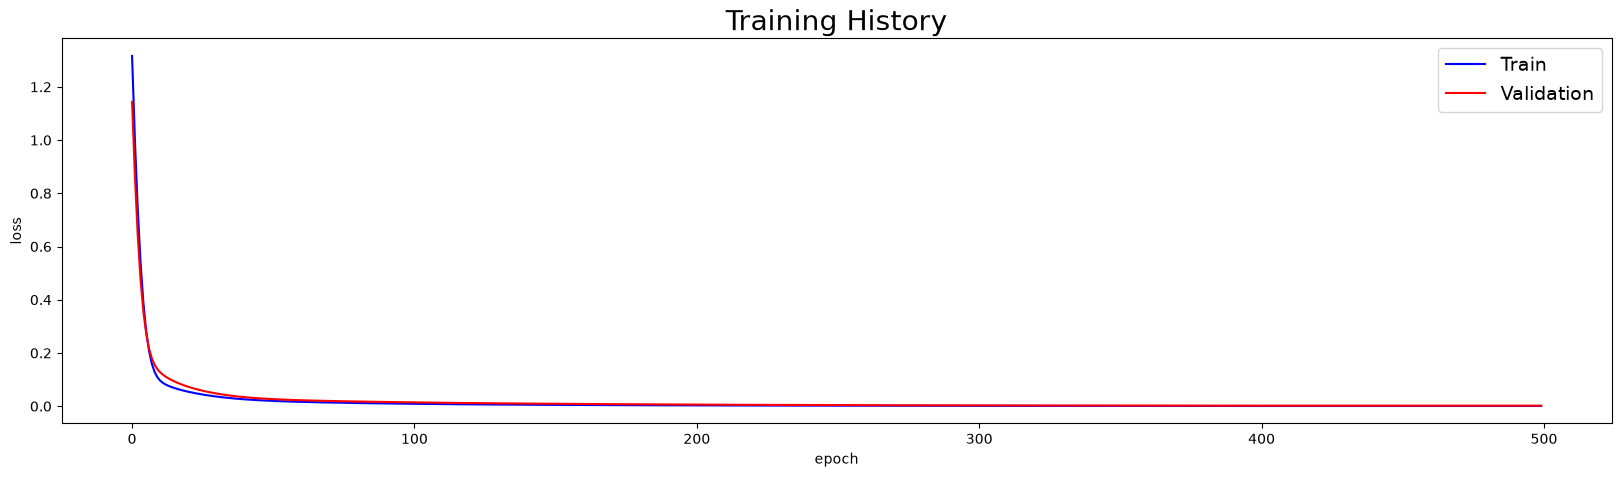

TrainData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.07  0.06  0.06  0.05  0.05  0.10  0.07
R2             1.00  1.00  1.00  1.00  1.00  0.99  1.00

TestData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.09  0.11  0.09  0.09  0.08  0.14  0.10
R2             0.99  0.99  0.99  1.00  1.00  0.99  0.99



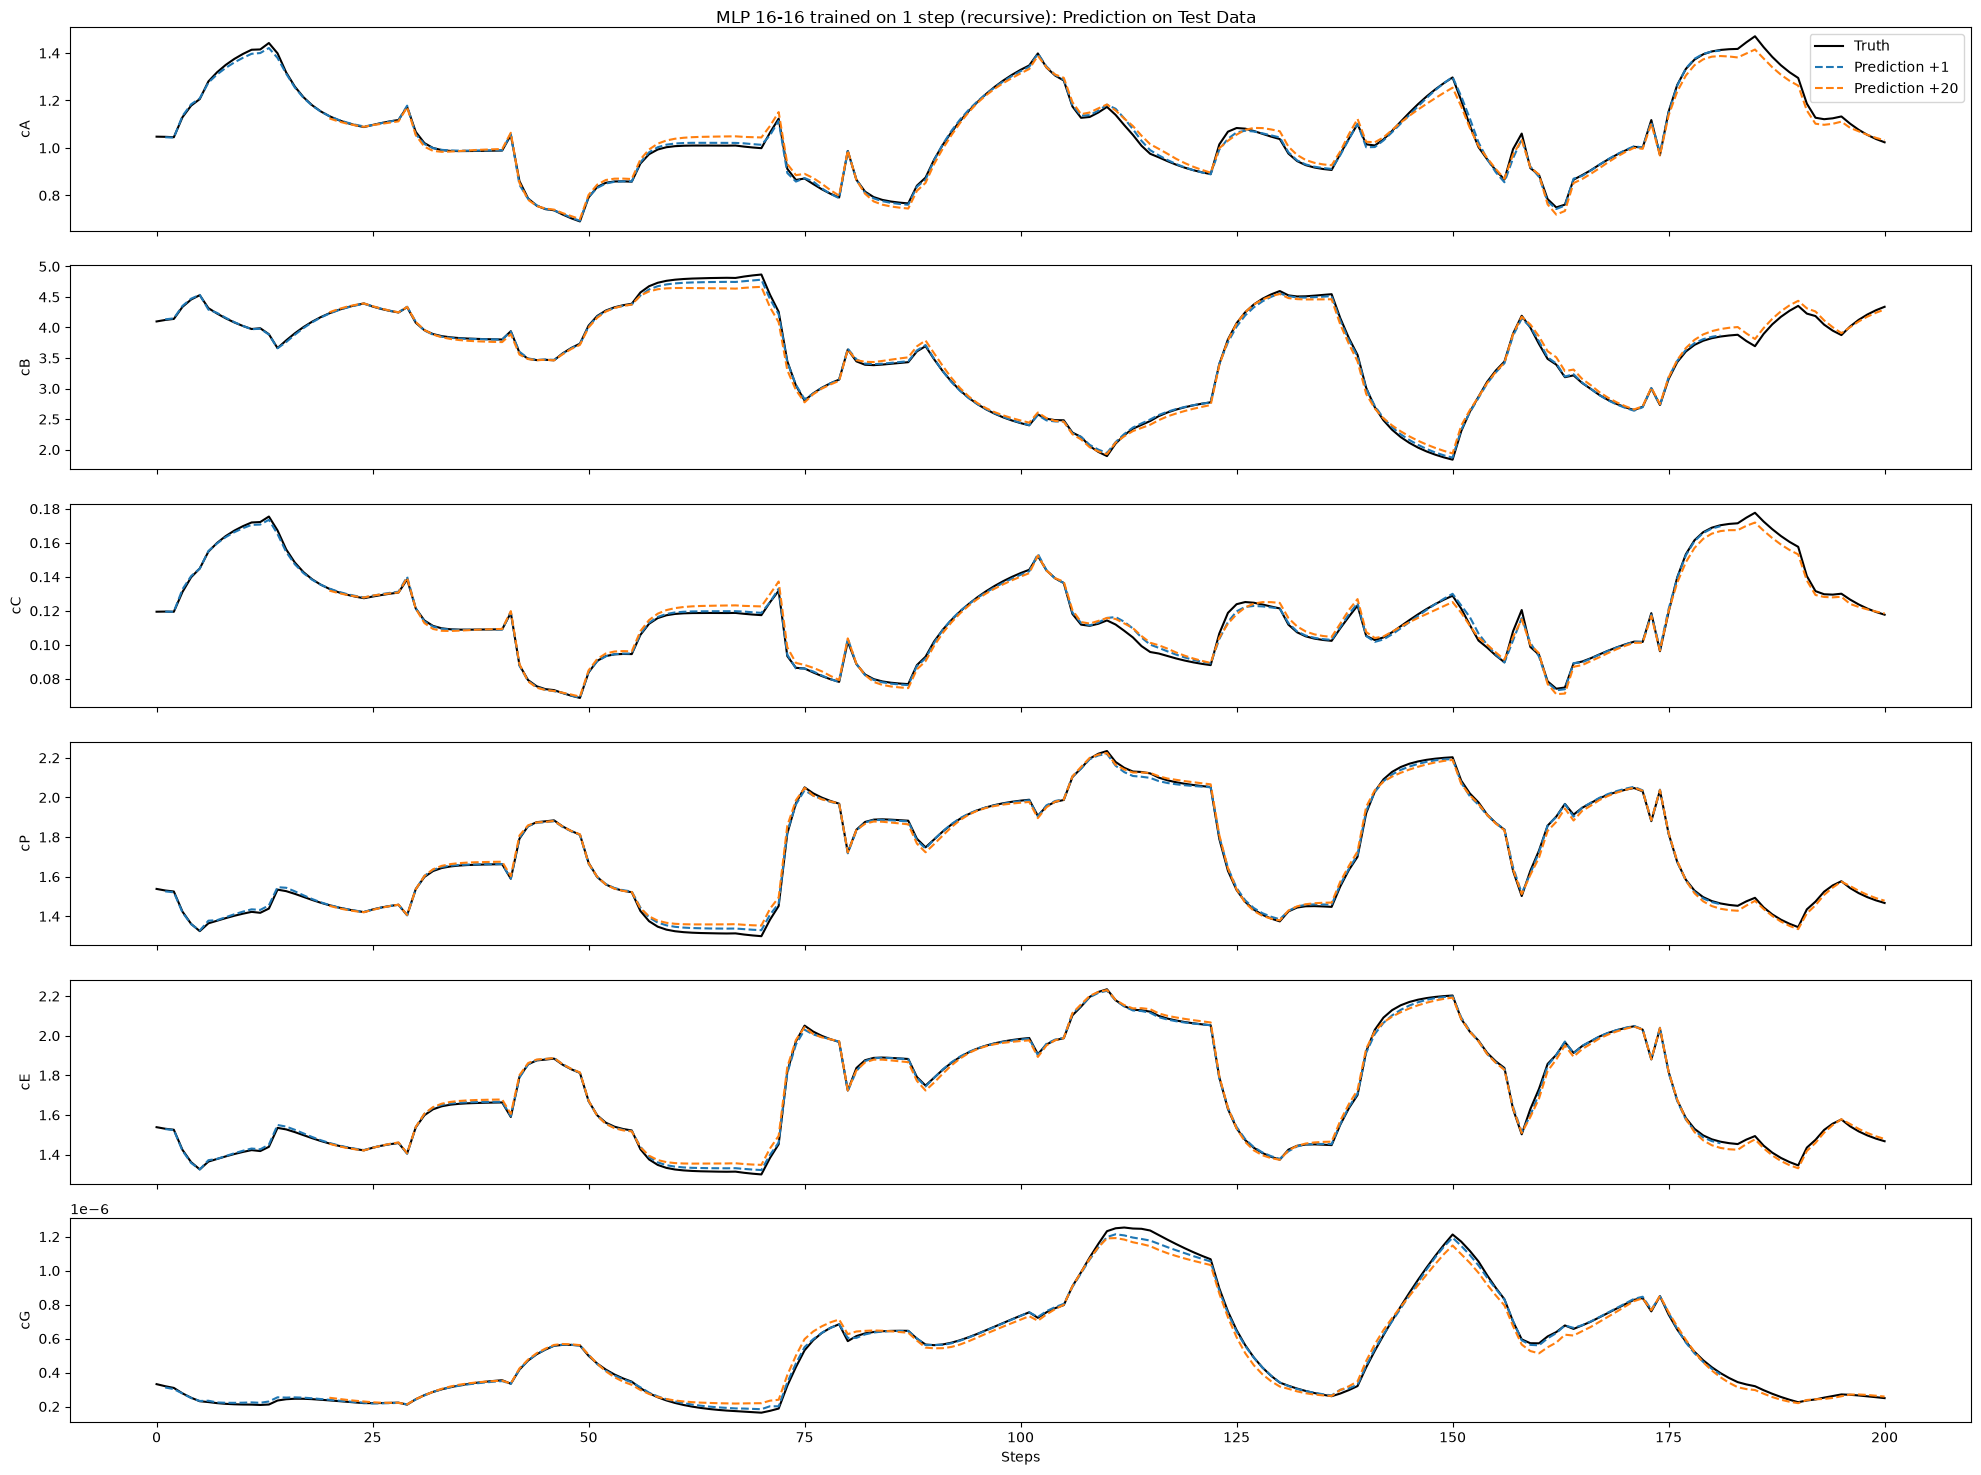

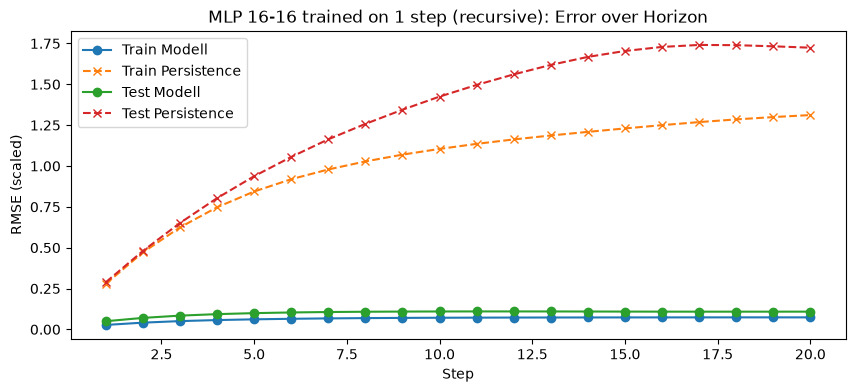

,model_name,direct_or_recursive,look_back,look_ahead,training_time_in_ms,inference_time,train_rmse,test_rmse,train_r2,test_r2
0,First principles,NaN,NaN,NaN,NaN,40.89,NaN,NaN,NaN,NaN
1,Test Run MLP,direct,0.0,20.0,3.21,3.25,0.54,0.69,0.71,0.62
2,MLP 16-16,direct,0.0,20.0,31.29,2.37,0.15,0.21,0.98,0.97
3,MLP 16-16 trained on 1 step,recursive,0.0,1.0,31.28,46.72,0.07,0.10,1.00,0.99


In [51]:
# MLP 1 step recursive trained on 1 step error
pipe = WindowPipeline(look_back=0, look_ahead=1, multistep=False)
pipe.fit(ytrain,Utrain)
Xtrain,Wtrain = pipe.transform(ytrain,Utrain)
Xval,Wval = pipe.transform(yval,Uval)

keras.utils.clear_session()

# Build Model
model = Sequential([
    Input(shape=(Xtrain.shape[1],)),
    Dense(16,activation='tanh'),
    Dense(16,activation='tanh'),
    Dense(Wtrain.shape[1],)
])

# Compile model
model.compile(loss='mean_squared_error', optimizer='adam',metrics=[keras.metrics.R2Score()])

# Train model
cb = [EarlyStopping(patience=30, restore_best_weights=True),    # stop when no improvement
      ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-5)]  # reduce learning rate on plateau

t0 = time.perf_counter()
history = model.fit(Xtrain, Wtrain, validation_data=(Xval, Wval),
                    epochs=500, batch_size=128,
                    callbacks=cb,
                    verbose=1)
training_time = time.perf_counter() - t0

# Save + Evaluate
model_bank["MLP 16-16 1 step recursive, 1 step error"] = (model,pipe,"recursive")
df_models = evaluate(model, pipe, "recursive", CFG.H, Utrain, ytrain, Utest, ytest, history, training_time, df_models, "MLP 16-16 trained on 1 step")

#### 3. Recursively used 1-step model trained on simulation error

Epoch 1/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 2s 49ms/step - loss: 0.9468 - r2_score: 0.0526 - val_loss: 0.8376 - val_r2_score: 0.0758 - learning_rate: 0.0010
Epoch 2/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.7182 - r2_score: 0.2820 - val_loss: 0.6818 - val_r2_score: 0.2585 - learning_rate: 0.0010
Epoch 3/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.5672 - r2_score: 0.4333 - val_loss: 0.5617 - val_r2_score: 0.3929 - learning_rate: 0.0010
Epoch 4/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.4508 - r2_score: 0.5497 - val_loss: 0.4565 - val_r2_score: 0.5089 - learning_rate: 0.0010
Epoch 5/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.3519 - r2_score: 0.6485 - val_loss: 0.3620 - val_r2_score: 0.6108 - learning_rate: 0.0010
Epoch 6/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - loss: 0.2737 - r2_score: 0.7266 - val_loss: 0.2954 - val_r2_score: 0.6819 - learning_rate: 0.0010
Epoch 7/500
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.2211 - r2_score: 0.7791 - val_lo

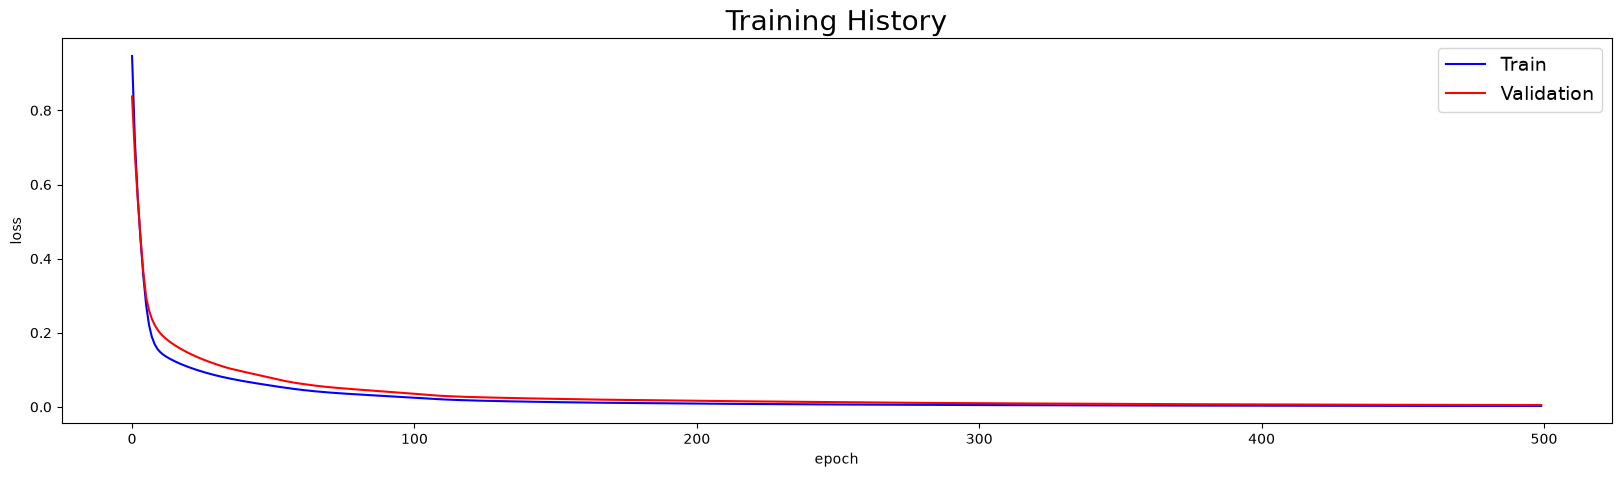

TrainData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.04  0.03  0.06  0.04  0.04  0.07  0.05
R2             1.00  1.00  1.00  1.00  1.00  0.99  1.00

TestData
                 cA    cB    cC    cP    cE    cG   all
RMSE (scaled)  0.06  0.07  0.07  0.06  0.06  0.12  0.08
R2             0.99  1.00  0.99  1.00  1.00  0.99  1.00



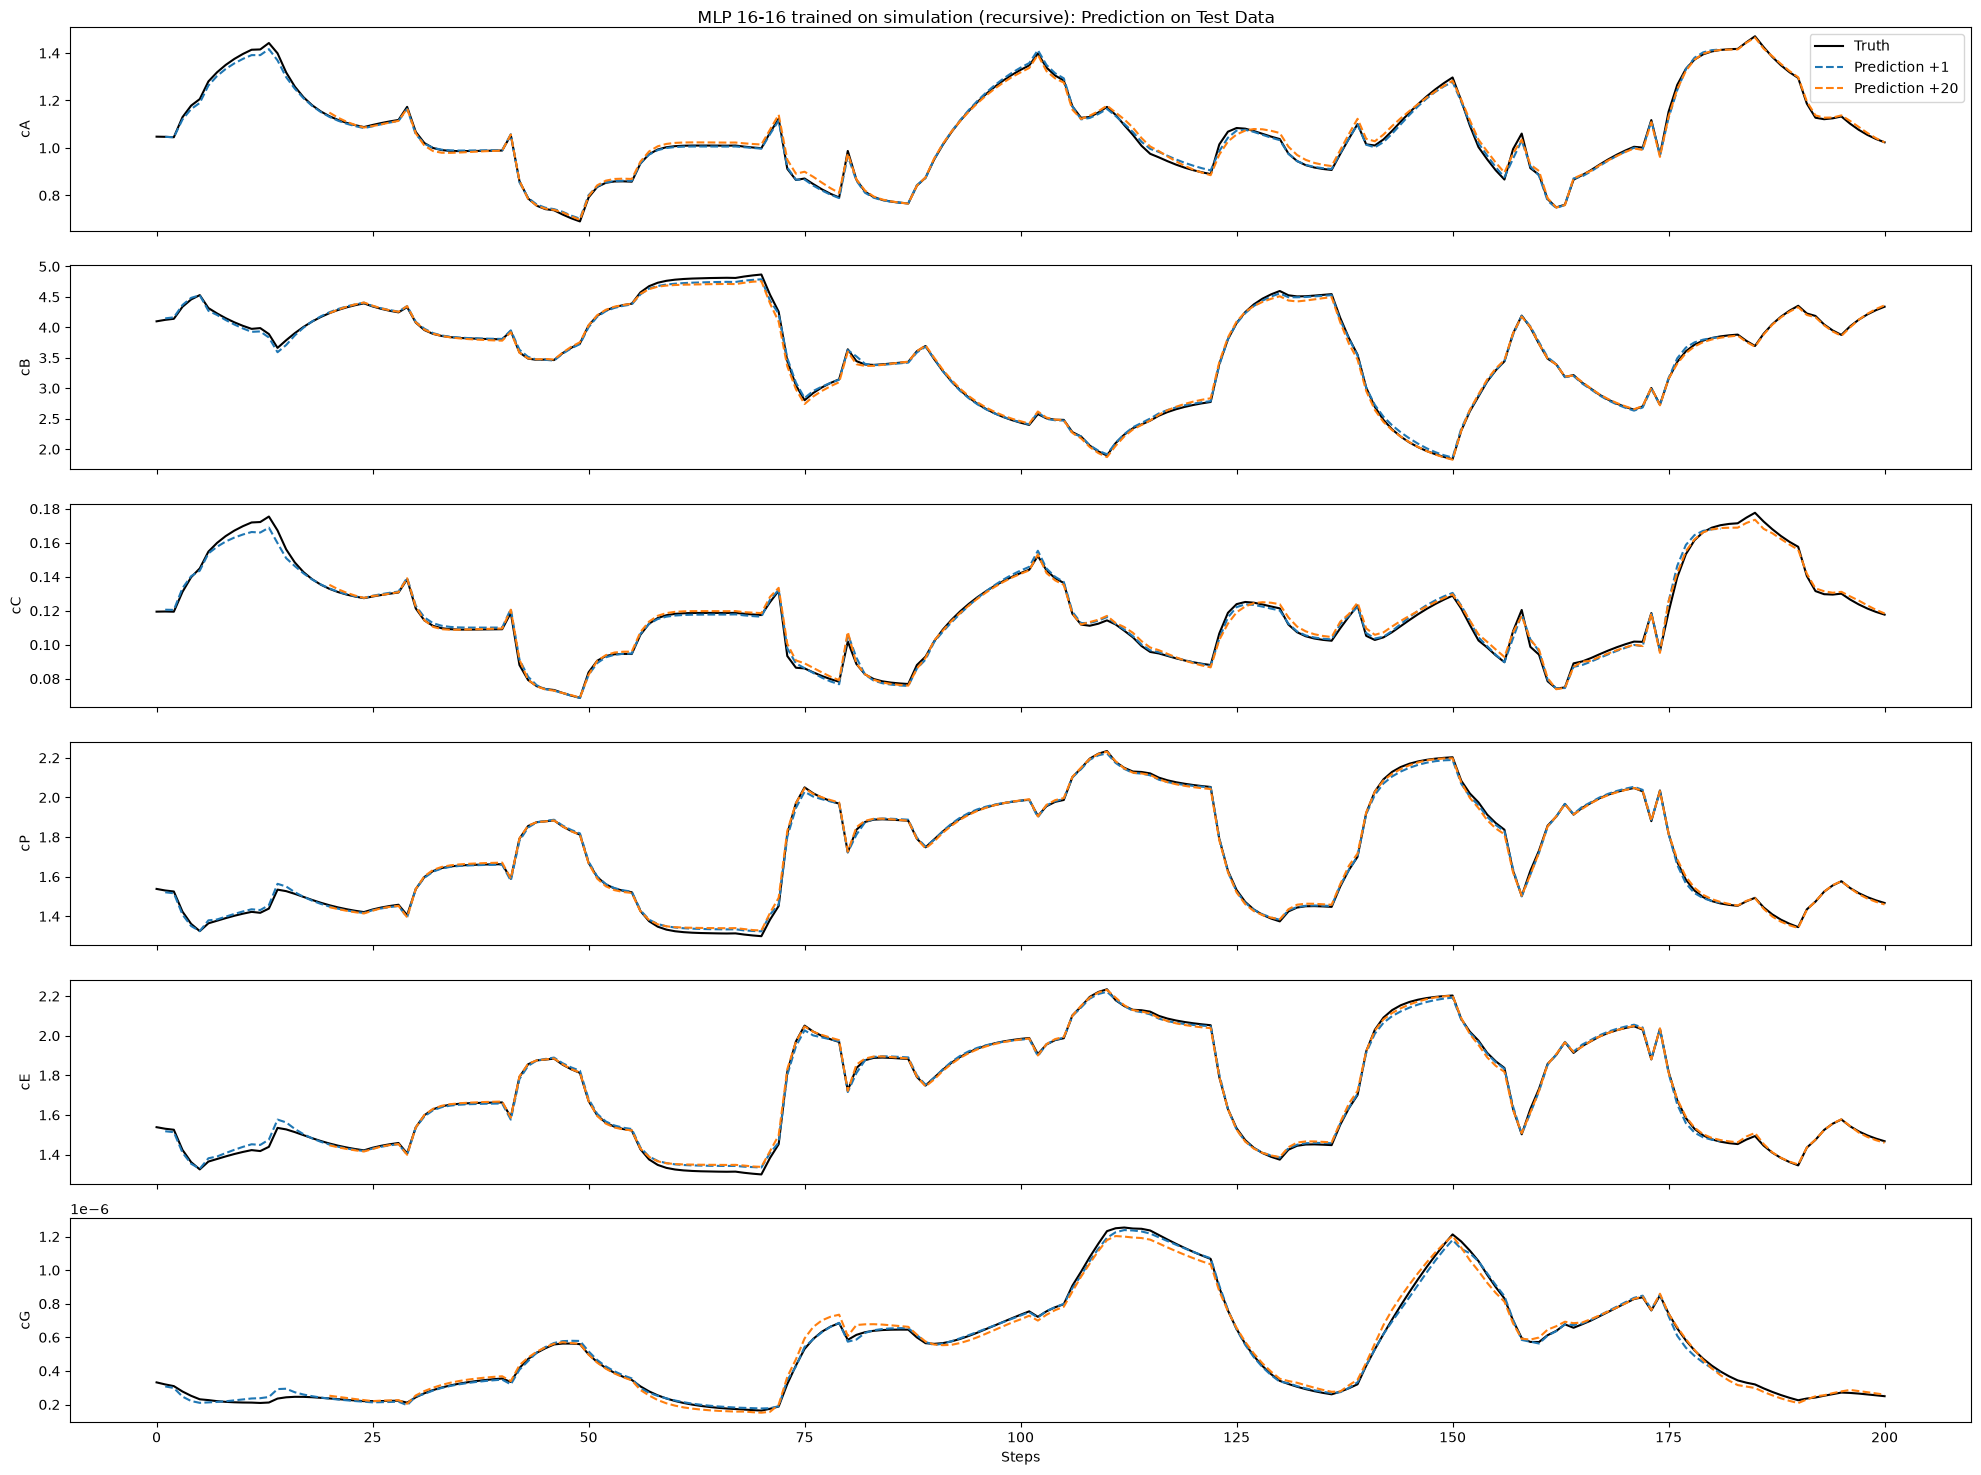

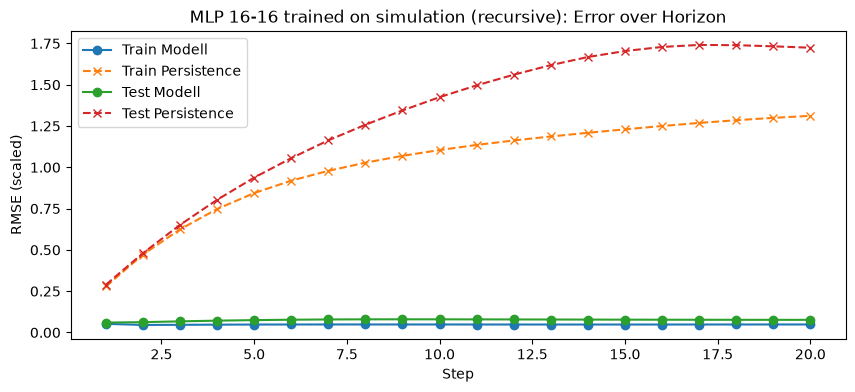

,model_name,direct_or_recursive,look_back,look_ahead,training_time_in_ms,inference_time,train_rmse,test_rmse,train_r2,test_r2
0,First principles,NaN,NaN,NaN,NaN,40.89,NaN,NaN,NaN,NaN
1,Test Run MLP,direct,0.0,20.0,3.21,3.25,0.54,0.69,0.71,0.62
2,MLP 16-16,direct,0.0,20.0,31.29,2.37,0.15,0.21,0.98,0.97
3,MLP 16-16 trained on 1 step,recursive,0.0,1.0,31.28,46.72,0.07,0.10,1.00,0.99
4,MLP 16-16 trained on simulation,recursive,0.0,20.0,38.37,47.63,0.05,0.08,1.00,1.00


In [52]:
# MLP 1 step recursive trained on simulation error
pipe = WindowPipeline(look_back=0, look_ahead=CFG.H, multistep=True)
pipe.fit(ytrain,Utrain)
Xtrain,Wtrain = pipe.transform(ytrain,Utrain)
Xval,Wval = pipe.transform(yval,Uval)

keras.utils.clear_session()

# Build Model f: one-step model [y(t), u(t)] -> y(t+1)
n_y, n_u, H = CFG.NY, CFG.NU, CFG.H
f = Sequential([Input(shape=(n_y + n_u,)),
                Dense(16, activation="tanh"),
                Dense(16, activation="tanh"),
                Dense(n_y)])

# Build Simulation Graph using f
inp = Input(shape=(n_y + H * n_u,))
y_step = inp[:, :n_y]                                                # start state y
outs = []
for h in range(H):
    u = inp[:, n_y + h * n_u : n_y + (h + 1) * n_u]             # Lookback=0: u(t+h)
    y_step = f(keras.ops.concatenate([y_step, u], axis=1))                # use f to predict 1 step ahead from last y
    outs.append(y_step)                                              # save prediction
model_loop = keras.Model(inp, keras.ops.concatenate(outs, axis=1))   # Model between Input and output, output shape: (B, H*n_y)

# Compile model
model_loop.compile(loss='mean_squared_error', optimizer='adam',metrics=[keras.metrics.R2Score()])

# Train model
cb = [EarlyStopping(patience=30, restore_best_weights=True),    # stop when no improvement
      ReduceLROnPlateau(factor=0.5, patience=10, min_lr=1e-5)]  # reduce learning rate on plateau

t0 = time.perf_counter()
history = model_loop.fit(Xtrain, Wtrain, validation_data=(Xval, Wval),
                    epochs=500, batch_size=128,
                    callbacks=cb,
                    verbose=1)
training_time = time.perf_counter() - t0

# Save + Evaluate
model_bank["MLP 16-16 1 step recursive, sim error"] = (f,pipe,"recursive")
df_models = evaluate(f, pipe, "recursive", CFG.H, Utrain, ytrain, Utest, ytest, history, training_time, df_models, "MLP 16-16 trained on simulation")

## N4SID and machine learning: shared evaluation in Python

Run the notebook training-export cell, fit the models using the updated MATLAB script, and run the ML training cells above before this section. A legacy numeric `n4sid_model.mat` can be read as a fallback, but its training provenance cannot be verified.

We compare persistence, every model in `model_bank`, and all exported N4SID baselines on **the same forecast starts, future inputs, and horizon duration**. The datasets are the notebook test partition and the original N4SID `validation.csv` generated by the N4SID data generator. Predictions target y(t+1), …, y(t+H). No future measured outputs are supplied during a forecast. N4SID's initial state is reconstructed from the current measured concentrations using the pseudoinverse of C; it is not optimized against the entire validation trajectory.

MAE and RMSE are reported per concentration in **mol/dm³**, with pooled physical and normalized scores. All normalized metrics use the notebook training-output standard deviations. These are **rolling-horizon forecast errors**, not the earlier MATLAB full-trajectory scores. Overlapping windows are separate forecasts. All eligible starts are evaluated by default; set `MAX_COMPARISON_WINDOWS` to an integer to limit runtime using evenly spaced starts.

**Sampling:** the ML model runs at `CFG.DT`. Finer external observations are downsampled; all models receive those same sampled inputs held on the ML grid. For coarser external data, inputs are held across native ML steps and predictions are scored only at actual recorded output times. No ground-truth outputs are interpolated. Models requiring past native-rate outputs (`look_back > 0`) need matching-rate data; the code rejects incompatible coarse data.

**Interpretation:** the original N4SID training experiment and the notebook ML training data differ in operating range, amount, and sampling. The training-provenance table labels this. Use the additional notebook-trained N4SID export to control those differences. The matrix C may also be ill-conditioned: instantaneous state reconstruction is an initialization choice, not a guarantee of an accurate state estimate. A past-only observer is a possible later improvement.

No N4SID entries are added to `model_bank`, whose existing entries are Keras models used by the later CasADi MPC cells. These additions compare surrogate forecast accuracy, not MPC control performance.


In [53]:
# Numeric N4SID adapter: no MATLAB engine is needed for notebook evaluation.
from scipy.io import loadmat


def load_n4sid_export(path):
    fields = ['A', 'B', 'C', 'D', 'Ts_min', 'TsTrain', 'uOffset',
              'yOffset', 'uScale', 'yScale', 'training_source',
              'training_U', 'training_Y', 'inputNames', 'outputNames']
    raw = loadmat(path, variable_names=fields, simplify_cells=True)
    out = {k: np.atleast_2d(np.asarray(raw[k], dtype=float))
           for k in ('A', 'B', 'C', 'D')}
    for k, size in [('uOffset', CFG.NU), ('uScale', CFG.NU),
                    ('yOffset', CFG.NY), ('yScale', CFG.NY)]:
        out[k] = np.asarray(raw[k], dtype=float).reshape(size)
        if not np.isfinite(out[k]).all():
            raise ValueError(f'{path}: invalid {k}')
    n = out['A'].shape[0]
    expected = {'A': (n, n), 'B': (n, CFG.NU),
                'C': (CFG.NY, n), 'D': (CFG.NY, CFG.NU)}
    for k, shape in expected.items():
        if out[k].shape != shape or not np.isfinite(out[k]).all():
            raise ValueError(f'{path}: invalid {k} matrix')
    if np.any(out['uScale'] <= 0) or np.any(out['yScale'] <= 0):
        raise ValueError(f'{path}: scaling must be positive')
    if not np.allclose(out['D'], 0, atol=1e-12):
        raise ValueError('This forecast adapter expects the fitted D=0 model.')
    out['Ts'] = float(np.asarray(raw.get('Ts_min', raw.get('TsTrain'))).item())
    if not np.isfinite(out['Ts']) or out['Ts'] <= 0:
        raise ValueError('Invalid model sampling time.')
    for key, expected_names in [('inputNames', CFG.names_U), ('outputNames', CFG.names_y)]:
        if key in raw:
            actual = tuple(str(v).strip() for v in np.atleast_1d(raw[key]))
            if actual != tuple(expected_names):
                raise ValueError(f'{key} channel order does not match CFG.')
    out['source'] = str(raw.get('training_source', 'original (legacy export)'))
    out['training_match'] = False
    if 'training_U' in raw and 'training_Y' in raw:
        train_u = np.asarray(raw['training_U'])
        train_y = np.asarray(raw['training_Y'])
        current_y = np.asarray(ytrain)[:len(Utrain)]
        out['training_match'] = (
            train_u.shape == np.shape(Utrain) and train_y.shape == current_y.shape
            and np.allclose(train_u, Utrain, rtol=1e-10, atol=1e-12)
            and np.allclose(train_y, current_y, rtol=1e-10, atol=1e-12)
            and np.isclose(out['Ts'], CFG.DT))
    if out['source'] == 'notebook' and not out['training_match']:
        raise ValueError('Notebook training data changed. Re-export training data and rerun MATLAB.')
    out['path'] = str(path)
    return out


def lift_n4sid(model, target_dt):
    # Exact integer-rate lifting under a zero-order-held input:
    # A_new = A**q; B_new = sum(A**j @ B, j=0,...,q-1).
    ratio = target_dt / model['Ts']
    q = int(round(ratio))
    if q < 1 or not np.isclose(ratio, q, rtol=1e-7, atol=1e-9):
        raise ValueError(f'Cannot map model Ts={model["Ts"]} to {target_dt} min by integer lifting.')
    out = dict(model)
    A, B = model['A'], model['B']
    power, total = np.eye(len(A)), np.zeros_like(B)
    for _ in range(q):
        total += power @ B
        power = power @ A
    out.update(A=power, B=total, Ts=float(target_dt))
    return out


def n4sid_rollout(model, initial_y, future_u):
    # initial_y: (windows, 6); future_u: (windows, native_steps, 2).
    # Initialize from CURRENT concentrations only, never future targets.
    ys = (initial_y - model['yOffset']) / model['yScale']
    us = (future_u - model['uOffset']) / model['uScale']
    x = ys @ np.linalg.pinv(model['C'], rcond=1e-10).T
    predictions = []
    for h in range(us.shape[1]):
        x = x @ model['A'].T + us[:, h] @ model['B'].T
        predictions.append((x @ model['C'].T) * model['yScale'] + model['yOffset'])
    result = np.stack(predictions, axis=1)
    if not np.isfinite(result).all():
        raise FloatingPointError('N4SID rollout diverged; inspect stability and initialization.')
    return result


def call_ml(model, X):
    return np.asarray(model.predict(X, batch_size=4096, verbose=0))


def ml_rollout(model, pipe, mode, Y, U, starts, future_u, factor):
    # Same input/target convention as predict_horizon, but explicitly supports
    # evaluating a native 1-minute model on a coarser observed output grid.
    lb = int(pipe.lb)
    Hnative = future_u.shape[1]
    if factor != 1 and lb:
        raise ValueError('Coarse-grid data do not contain the native-rate output history needed by look_back > 0.')
    y_hist = np.stack([Y[starts-j] for j in range(lb+1)], axis=1)
    y_hist = pipe.sc_y.transform(y_hist.reshape(-1, CFG.NY)).reshape(y_hist.shape)
    uf = pipe.sc_u.transform(future_u.reshape(-1, CFG.NU)).reshape(future_u.shape)
    up = [pipe.sc_u.transform(U[starts-j]) for j in range(1, lb+1)]
    if mode == 'direct':
        if int(pipe.la) != Hnative:
            raise ValueError('Direct model horizon does not match CFG.H; compare it separately.')
        X = np.hstack([y_hist[:, j] for j in range(lb+1)] + up
                      + [uf[:, j] for j in range(Hnative)])
        scaled = call_ml(model, X).reshape(len(starts), Hnative, CFG.NY)
    elif mode == 'recursive':
        preds = []
        for h in range(Hnative):
            past = [uf[:, h-j] if h-j >= 0 else up[j-h-1]
                    for j in range(1, lb+1)]
            X = np.hstack([y_hist[:, j] for j in range(lb+1)] + past + [uf[:, h]])
            next_y = call_ml(model, X).reshape(len(starts), CFG.NY)
            preds.append(next_y)
            y_hist = np.concatenate([next_y[:, None, :], y_hist[:, :-1]], axis=1)
        scaled = np.stack(preds, axis=1)
    else:
        raise ValueError(f'Unsupported ML mode: {mode}')
    result = pipe.sc_y.inverse_transform(scaled.reshape(-1, CFG.NY)).reshape(scaled.shape)
    if not np.isfinite(result).all():
        raise FloatingPointError('ML predictions contain nonfinite values.')
    return result


def read_comparison_csv(path):
    frame = pd.read_csv(path).sort_values('time_min')
    cols = ['time_min', *CFG.names_U, *CFG.names_y]
    values = frame[cols].to_numpy(dtype=float)
    if len(frame) < 2 or not np.isfinite(values).all():
        raise ValueError(f'Invalid comparison data: {path}')
    diffs = np.diff(frame.time_min)
    dt = float(np.median(diffs))
    if dt <= 0 or not np.allclose(diffs, dt, rtol=1e-6, atol=1e-8):
        raise ValueError(f'Nonuniform timestamps: {path}')
    return frame, dt


def prepare_dataset(name, U, Y, dt, max_windows, look_back):
    U, Y = np.asarray(U, float), np.asarray(Y, float)
    notes = []
    if U.ndim != 2 or Y.ndim != 2 or U.shape[1] != CFG.NU or Y.shape[1] != CFG.NY:
        raise ValueError('Invalid dataset dimensions.')
    if not np.isfinite(U).all() or not np.isfinite(Y).all():
        raise ValueError('Nonfinite dataset values.')
    # Fine external observations: use the ML grid. No output interpolation.
    # All models receive the same sampled/held inputs, even when the original
    # finer input changed between these sampled points.
    if dt < CFG.DT and not np.isclose(dt, CFG.DT):
        stride = int(round(CFG.DT / dt))
        if not np.isclose(stride * dt, CFG.DT):
            raise ValueError('Fine dataset interval must divide CFG.DT.')
        U, Y = U[::stride], Y[::stride]
        notes.append(f'Downsampled observations by {stride}; sampled inputs held on the ML grid.')
        dt = float(CFG.DT)
    factor = int(round(dt / CFG.DT))
    if factor < 1 or not np.isclose(factor * CFG.DT, dt):
        raise ValueError('Dataset interval must be an integer multiple of CFG.DT.')
    if CFG.H % factor:
        raise ValueError('CFG.H duration must be divisible by the observed output interval.')
    if factor != 1:
        if look_back:
            raise ValueError('Coarse data cannot provide native-rate measured histories for look_back > 0.')
        notes.append(f'Inputs repeated {factor} times; score only actual recorded outputs, without interpolation.')
    Hobs = CFG.H // factor
    # y can have one terminal state beyond the final input.
    final_start = min(len(U) - Hobs, len(Y) - 1 - Hobs)
    candidates = np.arange(look_back, final_start + 1)
    if len(candidates) == 0:
        raise ValueError(f'{name}: insufficient data for the configured horizon.')
    if max_windows is not None and len(candidates) > max_windows:
        candidates = candidates[np.linspace(0, len(candidates)-1, max_windows, dtype=int)]
        notes.append(f'Using {len(candidates)} evenly spaced forecast starts.')
    future = U[candidates[:, None] + np.arange(Hobs)]
    future = np.repeat(future, factor, axis=1)
    target = Y[candidates[:, None] + np.arange(1, Hobs+1)]
    return dict(name=name, U=U, Y=Y, dt=dt, factor=factor,
                starts=candidates, future=future, target=target,
                minutes=np.arange(1, Hobs+1)*dt, notes=' '.join(notes))


def score_forecasts(dataset, name, truth, prediction, common_scale):
    error = prediction-truth
    scaled = error/common_scale
    rows = []
    for j, species in enumerate(CFG.names_y):
        rows.append(dict(dataset=dataset, model=name, output=species,
                         MAE=np.mean(np.abs(error[:, :, j])),
                         RMSE=np.sqrt(np.mean(error[:, :, j]**2)),
                         R2=r2_score(truth[:, :, j].ravel(), prediction[:, :, j].ravel())))
    summary = dict(dataset=dataset, model=name,
                   MAE=np.mean(np.abs(error)), RMSE=np.sqrt(np.mean(error**2)),
                   scaled_MAE=np.mean(np.abs(scaled)), scaled_RMSE=np.sqrt(np.mean(scaled**2)))
    horizon = np.sqrt(np.mean(scaled**2, axis=(0, 2)))
    return rows, summary, horizon


In [54]:
# Run the model-training cells above before this section.
if not model_bank:
    raise RuntimeError('Train the ML models above so model_bank is populated.')

export_paths = sorted(N4SID_DIR.glob('n4sid_export_*.mat'))
if not export_paths:
    legacy = N4SID_DIR / 'n4sid_model.mat'
    if legacy.exists():
        export_paths = [legacy]
        print('Using existing MATLAB numeric matrices. Run the updated MATLAB script for fresh, training-verified exports.')
    else:
        raise FileNotFoundError('Run n4sid1.m in MATLAB, then rerun this cell.')

n4sid_models = {}
provenance_rows = []
for path in export_paths:
    base = load_n4sid_export(path)
    name = 'N4SID / ' + base['source']
    n4sid_models[name] = lift_n4sid(base, CFG.DT)
    provenance_rows.append(dict(
        model=name, training_source=base['source'],
        same_training_samples_as_ML=base['training_match'],
        exported_Ts_min=base['Ts'], evaluation_Ts_min=CFG.DT,
        spectral_radius=float(np.max(np.abs(np.linalg.eigvals(base['A'])))),
        C_rank=int(np.linalg.matrix_rank(base['C'])),
        file=base['path']))
df_n4sid_provenance = pd.DataFrame(provenance_rows)
display(df_n4sid_provenance)
if not df_n4sid_provenance.same_training_samples_as_ML.any():
    print('Training data differ: this is a model-plus-training-data comparison. Export notebook_train.csv and rerun MATLAB for a matched-data N4SID baseline.')

# No full-test-set initial-state optimization is used.
# The current measured concentration initializes each forecast via pinv(C).
MAX_COMPARISON_WINDOWS = None  # All eligible starts; set an integer to limit runtime.
common_look_back = max(int(pipe.lb) for _, pipe, _ in model_bank.values())
comparison_datasets = [prepare_dataset(
    'Notebook test', Utest, ytest, CFG.DT,
    MAX_COMPARISON_WINDOWS, common_look_back)]

original_frame, original_dt = read_comparison_csv(N4SID_DIR / 'validation.csv')
comparison_datasets.append(prepare_dataset(
    'Original validation', original_frame[list(CFG.names_U)].to_numpy(),
    original_frame[list(CFG.names_y)].to_numpy(), original_dt,
    MAX_COMPARISON_WINDOWS, common_look_back))

display(pd.DataFrame([dict(
    dataset=d['name'], starts=len(d['starts']),
    horizon_minutes=CFG.H*CFG.DT, scored_steps=len(d['minutes']),
    observed_dt_minutes=d['dt'], assumptions=d['notes'])
    for d in comparison_datasets]))


,model,training_source,same_training_samples_as_ML,exported_Ts_min,evaluation_Ts_min,spectral_radius,C_rank,file
0,N4SID / notebook,notebook,True,1.0,1,0.821359,5,/Users/nilsbulitta/Documents/GitHub/data_scien...
1,N4SID / original,original,False,0.1,1,0.982008,4,/Users/nilsbulitta/Documents/GitHub/data_scien...


,dataset,starts,horizon_minutes,scored_steps,observed_dt_minutes,assumptions
0,Notebook test,181,20,20,1.0,
1,Original validation,580,20,20,1.0,Downsampled observations by 10; sampled inputs...


In [55]:
# Shared, train-only normalization for aggregate scores across all models.
comparison_scale = np.std(np.asarray(ytrain), axis=0, ddof=0)
if np.any(comparison_scale <= 0):
    raise ValueError('Training outputs must have nonzero variance.')

comparison_predictions = {}
metric_rows, summary_rows, horizon_rows = [], [], []
for dataset in comparison_datasets:
    name = dataset['name']
    starts, truth = dataset['starts'], dataset['target']
    factor = dataset['factor']
    select = np.arange(factor-1, CFG.H, factor)
    predictors = {'Persistence': lambda d=dataset: np.repeat(
        d['Y'][d['starts'], None, :], len(d['minutes']), axis=1)}
    for label, baseline in n4sid_models.items():
        predictors[label] = lambda b=baseline, d=dataset, s=select: n4sid_rollout(
            b, d['Y'][d['starts']], d['future'])[:, s]
    for label, (network, pipeline, mode) in model_bank.items():
        if label in predictors:
            raise ValueError(f'Duplicate model label: {label}')
        predictors[label] = lambda m=network, p=pipeline, k=mode, d=dataset, s=select: ml_rollout(
            m, p, k, d['Y'], d['U'], d['starts'], d['future'], d['factor'])[:, s]
    for label, predict in predictors.items():
        # Includes preprocessing/initialization and prediction, excludes scoring.
        # Batch throughput is not comparable to the earlier single-window timers.
        tic = time.perf_counter()
        pred = predict()
        batch_ms = (time.perf_counter()-tic)*1000
        if pred.shape != truth.shape:
            raise ValueError(f'{name}/{label}: prediction/target shapes differ.')
        rows, summary, horizon_errors = score_forecasts(
            name, label, truth, pred, comparison_scale)
        summary.update(windows=len(starts), scored_steps=len(select),
                       horizon_min=CFG.H*CFG.DT,
                       batch_ms=batch_ms, batch_ms_per_window=batch_ms/len(starts))
        metric_rows.extend(rows)
        summary_rows.append(summary)
        horizon_rows.extend(dict(dataset=name, model=label, minutes=minute, scaled_RMSE=value)
                            for minute, value in zip(dataset['minutes'], horizon_errors))
        comparison_predictions[(name, label)] = pred

df_comparison_per_output = pd.DataFrame(metric_rows)
df_comparison = pd.DataFrame(summary_rows).sort_values(['dataset', 'scaled_RMSE'])
df_comparison_horizon = pd.DataFrame(horizon_rows)
print('Aggregate MAE/RMSE are pooled over forecast windows, steps and outputs.')
print('Physical MAE/RMSE: mol/dm³. Scaled errors use the same ML-training standard deviations for every model.')
display(df_comparison.round(6))
print('Per-output errors in mol/dm³:')
display(df_comparison_per_output.round(6))

# Relative reduction in pooled physical RMSE versus each N4SID baseline.
# Positive values indicate lower error than the indicated N4SID baseline.
improvement_rows = []
for dataset_name, group in df_comparison.groupby('dataset'):
    for baseline_name in n4sid_models:
        reference = float(group.loc[group.model == baseline_name, 'RMSE'].iloc[0])
        for _, row in group.iterrows():
            improvement_rows.append(dict(dataset=dataset_name, model=row.model,
                reference=baseline_name,
                RMSE_reduction_percent=(100*(1-row.RMSE/reference) if reference > 0 else np.nan)))
df_comparison_improvement = pd.DataFrame(improvement_rows)
display(df_comparison_improvement.round(2))


Aggregate MAE/RMSE are pooled over forecast windows, steps and outputs.
Physical MAE/RMSE: mol/dm³. Scaled errors use the same ML-training standard deviations for every model.


,dataset,model,MAE,RMSE,scaled_MAE,scaled_RMSE,windows,scored_steps,horizon_min,batch_ms,batch_ms_per_window
6,Notebook test,"MLP 16-16 1 step recursive, sim error",0.009973,0.019679,0.054046,0.075545,181,20,20,887.944125,4.905769
5,Notebook test,"MLP 16-16 1 step recursive, 1 step error",0.015596,0.030730,0.075160,0.102373,181,20,20,894.318625,4.940987
4,Notebook test,MLP 16-16 Multistep direct,0.030022,0.053139,0.152032,0.208112,181,20,20,56.176291,0.310366
1,Notebook test,N4SID / notebook,0.017829,0.028485,0.144130,0.223089,181,20,20,0.678750,0.003750
2,Notebook test,N4SID / original,0.017336,0.028249,0.188451,0.371917,181,20,20,0.511292,0.002825
3,Notebook test,Test Run MLP,0.121374,0.212532,0.544254,0.694149,181,20,20,63.041458,0.348295
0,Notebook test,Persistence,0.227461,0.432191,1.010072,1.381034,181,20,20,0.059125,0.000327
13,Original validation,"MLP 16-16 1 step recursive, sim error",0.009682,0.016866,0.036977,0.046331,580,20,20,866.404375,1.493801
9,Original validation,N4SID / original,0.003829,0.007673,0.028059,0.047872,580,20,20,1.778250,0.003066
12,Original validation,"MLP 16-16 1 step recursive, 1 step error",0.010976,0.018574,0.044318,0.054797,580,20,20,862.481000,1.487036


Per-output errors in mol/dm³:


,dataset,model,output,MAE,RMSE,R2
0,Notebook test,Persistence,cA,0.171936,0.218736,-0.472991
1,Notebook test,Persistence,cB,0.690421,0.928665,-0.308838
2,Notebook test,Persistence,cC,0.023558,0.030038,-0.456456
3,Notebook test,Persistence,cP,0.239424,0.323703,-0.363743
4,Notebook test,Persistence,cE,0.239425,0.323703,-0.363743
...,...,...,...,...,...,...
79,Original validation,"MLP 16-16 1 step recursive, sim error",cB,0.033242,0.037610,0.861694
80,Original validation,"MLP 16-16 1 step recursive, sim error",cC,0.000815,0.001155,0.941136
81,Original validation,"MLP 16-16 1 step recursive, sim error",cP,0.009766,0.011335,0.878961
82,Original validation,"MLP 16-16 1 step recursive, sim error",cE,0.007979,0.009685,0.911644


,dataset,model,reference,RMSE_reduction_percent
0,Notebook test,"MLP 16-16 1 step recursive, sim error",N4SID / notebook,30.92
1,Notebook test,"MLP 16-16 1 step recursive, 1 step error",N4SID / notebook,-7.88
2,Notebook test,MLP 16-16 Multistep direct,N4SID / notebook,-86.55
3,Notebook test,N4SID / notebook,N4SID / notebook,0.00
4,Notebook test,N4SID / original,N4SID / notebook,0.83
5,Notebook test,Test Run MLP,N4SID / notebook,-646.12
6,Notebook test,Persistence,N4SID / notebook,-1417.26
7,Notebook test,"MLP 16-16 1 step recursive, sim error",N4SID / original,30.34
8,Notebook test,"MLP 16-16 1 step recursive, 1 step error",N4SID / original,-8.78
9,Notebook test,MLP 16-16 Multistep direct,N4SID / original,-88.11


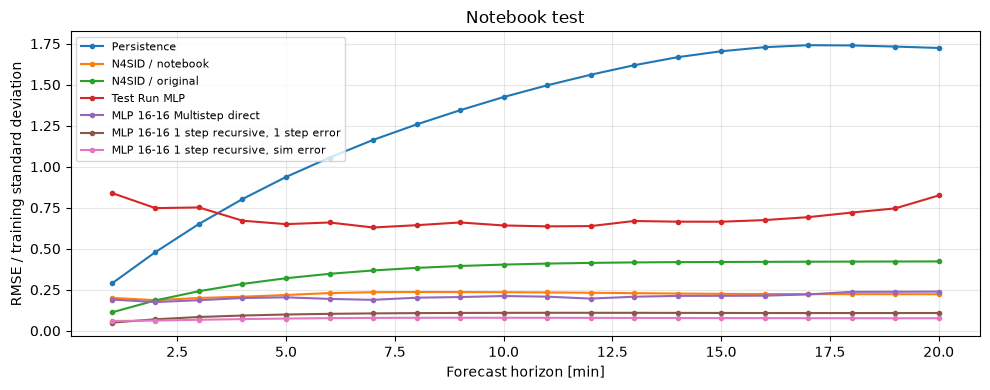

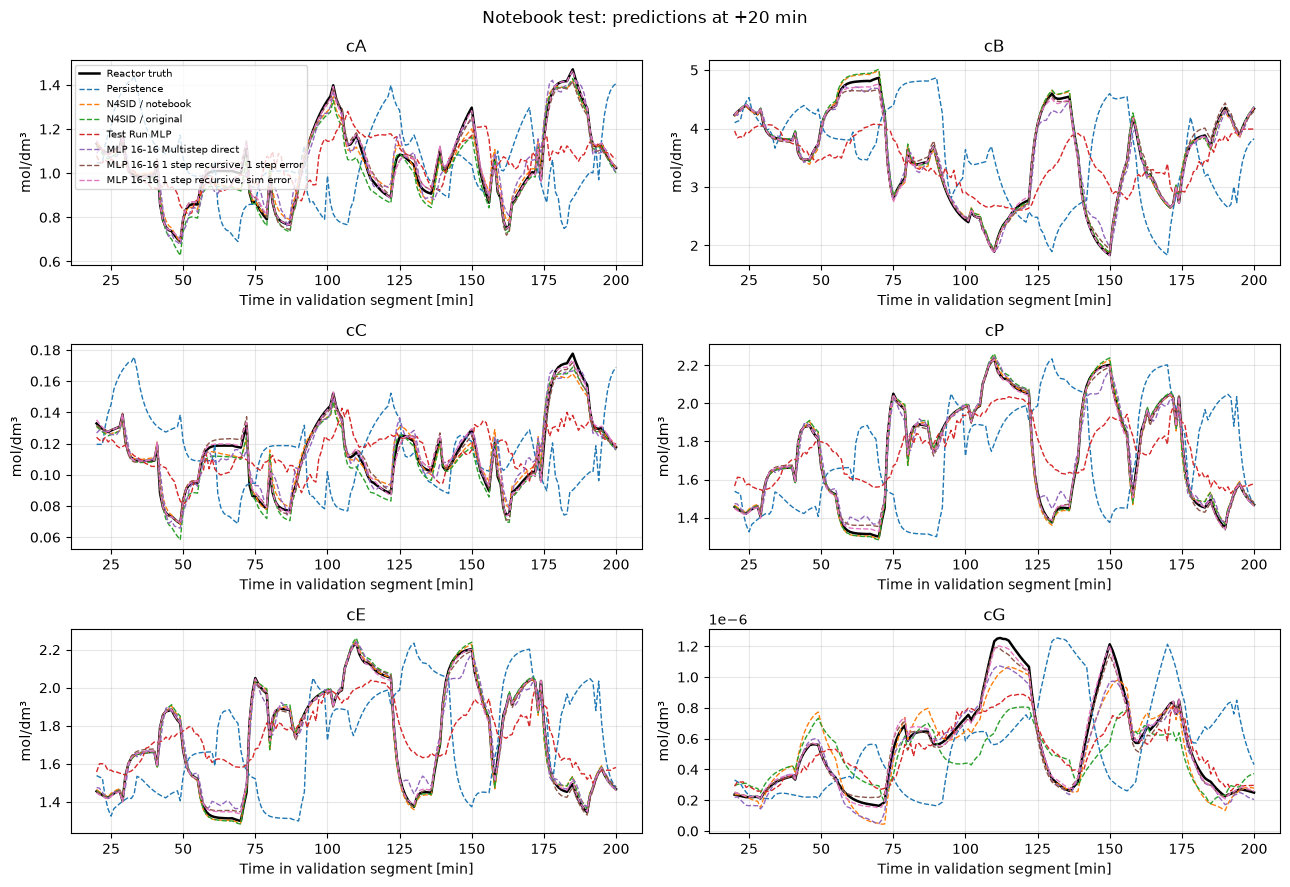

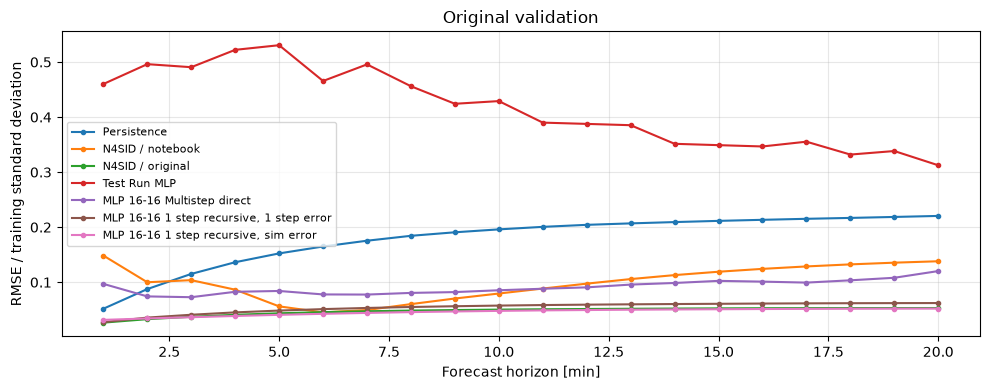

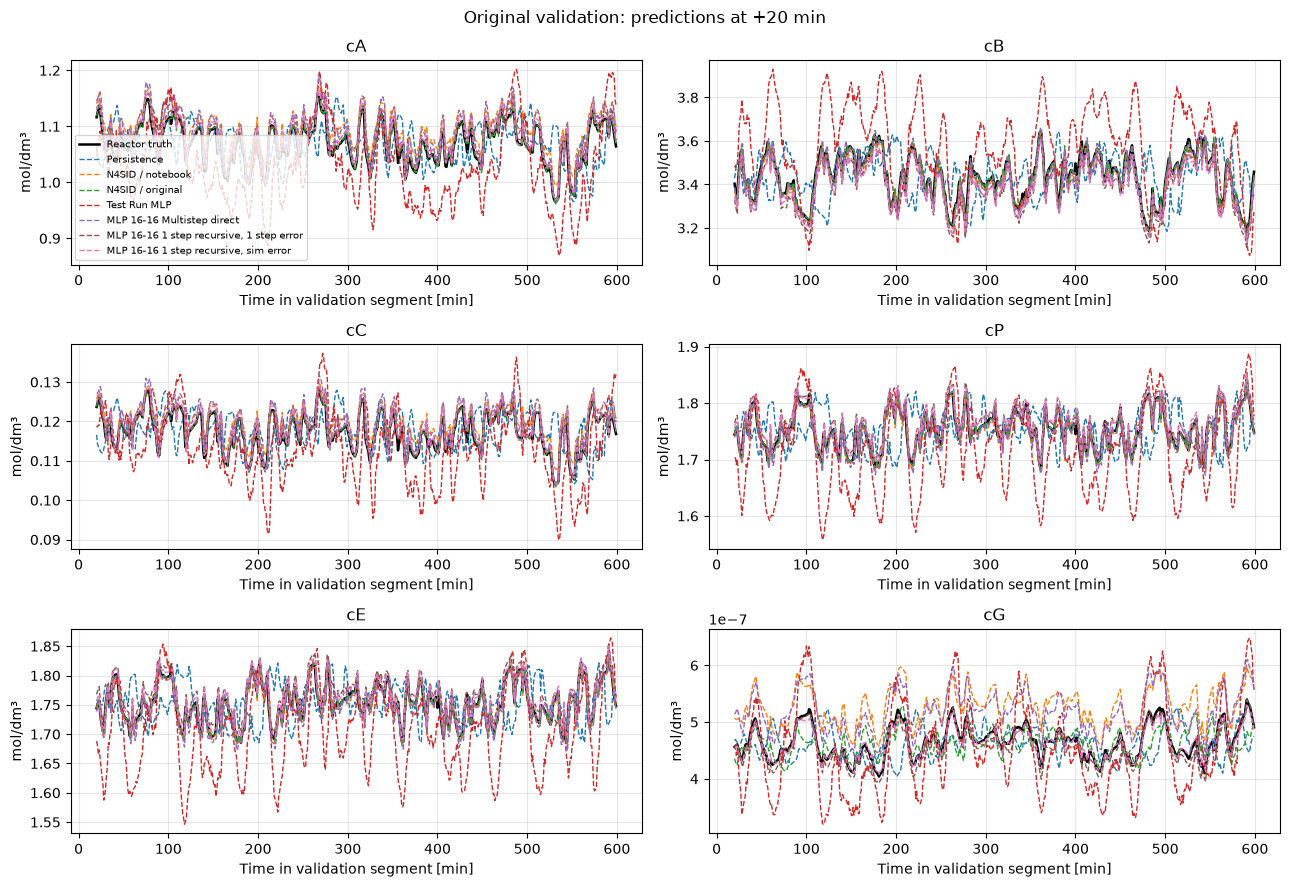

Notebook evaluation tables saved to /Users/nilsbulitta/Documents/GitHub/data_science_project_26fall/data/n4sid/notebook_evaluation


In [56]:
# Horizon error curves and final-horizon concentration predictions.
for dataset in comparison_datasets:
    name = dataset['name']
    subset = df_comparison_horizon.query('dataset == @name')
    fig, ax = plt.subplots(figsize=(10, 4))
    for label, group in subset.groupby('model', sort=False):
        ax.plot(group.minutes, group.scaled_RMSE, marker='.', label=label)
    ax.set(xlabel='Forecast horizon [min]', ylabel='RMSE / training standard deviation', title=name)
    ax.legend(fontsize=8); ax.grid(alpha=.3)
    plt.tight_layout(); plt.show()

    fig, axes = plt.subplots(3, 2, figsize=(13, 9))
    x = (dataset['starts'] + len(dataset['minutes'])) * dataset['dt']
    for j, ax in enumerate(axes.ravel()):
        ax.plot(x, dataset['target'][:, -1, j], 'k', lw=1.8, label='Reactor truth')
        for (dataset_name, label), pred in comparison_predictions.items():
            if dataset_name == name:
                ax.plot(x, pred[:, -1, j], '--', lw=1, label=label)
        ax.set(title=CFG.names_y[j], xlabel='Time in validation segment [min]', ylabel='mol/dm³')
        ax.grid(alpha=.3)
    axes.ravel()[0].legend(fontsize=7)
    fig.suptitle(f'{name}: predictions at +{CFG.H*CFG.DT:g} min')
    plt.tight_layout(); plt.show()

COMPARISON_DIR.mkdir(parents=True, exist_ok=True)
for name, frame in {
    'summary': df_comparison,
    'per_output': df_comparison_per_output,
    'per_horizon': df_comparison_horizon,
    'improvement_vs_n4sid': df_comparison_improvement,
    'n4sid_provenance': df_n4sid_provenance,
}.items():
    frame.to_csv(COMPARISON_DIR / f'{name}.csv', index=False)
comparison_settings = dict(
    native_dt_min=float(CFG.DT), horizon_steps=int(CFG.H),
    max_windows=(None if MAX_COMPARISON_WINDOWS is None else int(MAX_COMPARISON_WINDOWS)),
    initialization='Current measured concentrations only; N4SID uses pinv(C). No future outputs.',
    metrics='Rolling-horizon forecasts; overlapping forecasts count as separate forecast errors.',
    datasets=[dict(name=d['name'], dt_min=d['dt'], notes=d['notes']) for d in comparison_datasets])
(COMPARISON_DIR / 'settings.json').write_text(json.dumps(comparison_settings, indent=2))
print('Notebook evaluation tables saved to', COMPARISON_DIR)


#### 4. Compare recursive models on longer Horizon

## Buid Model for Prediction + Softsensor

## Implement Own MPC

In [57]:
# Settings
from scipy.optimize import minimize
pA,pB,pP,pE = 7.623, 11.434, 114.338, 5.184 # Component Prices [$/mol]
U_lo, U_hi = np.asarray(U_lo), np.asarray(U_hi)

# Prediction
def pred_fp(y0,U,step,pipe=None):
    y = y0
    ylog = []
    for u in U:
        y = step(y,u,CFG.DT)
        ylog.append(y)

    return np.array(ylog) # (len(U),n_y)

def pred_ml_dir(y0,U,model,pipe):
    X = np.concatenate([pipe.sc_y.transform(y0[None,:])[0],pipe.sc_u.transform(U).ravel()])[None,:] # scaled + windows input for mlp
    Y = model(X).numpy().reshape(CFG.H,CFG.NY)
    return pipe.sc_y.inverse_transform(Y)

def pred_ml_rec(y0, U, model, pipe):
    # U: (H,2) physical plan, pipe = one-step pipeline, model predicts y_{t+1} from [y_t, u_t]
    y = y0
    Y = []
    for u in U:
        x = np.concatenate([pipe.sc_y.transform(y[None, :])[0],
                            pipe.sc_u.transform(u[None, :])[0]])[None, :]       # (1, n_y + 2), layout [y_t, u_t]
        y = pipe.sc_y.inverse_transform(model(x, training=False).numpy())[0]    # back to physical, (n_y,)
        Y.append(y)
    return np.array(Y)     

# Cost
def cost(y,U):
    QB = U[:,0]
    cP = y[:,3]
    cE = y[:,4]
    l = params["QA"] * params["cA0"] * pA + QB * params["cB0"] * pB - (params["QA"]+QB) * (cP * pP + cE * pE)    # $/min for every step
    L = l.sum() * CFG.DT                                                               # $ Cost over all steps
    return L

# MPC Step
n_blocks=4
def z_to_U(z):  # z = [0,1] scaled for better optimization
    U = U_lo + z.reshape(n_blocks, 2) * (U_hi-U_lo)    # z ist 1d for minimize
    return np.repeat(U, CFG.H // n_blocks, axis=0)

def mpc_step(predict_fun, model, pipe, y_now, z0):
    objective = lambda z: cost(predict_fun(y_now,z_to_U(z),model,pipe),z_to_U(z))
    sol = minimize(objective, z0, bounds=[(0,1)]*len(z0), method='L-BFGS-B', options=dict(maxiter=20, eps=1e-3))
    return z_to_U(sol.x)[0], sol.x  # first input in physical form to apply, whole input plan in scaled form for initialization


# Run MPC in closed loop
def run_mpc(predict_fun, model, pipe, step, ystart, n_sim):
    ylog, ulog, tlog = [ystart], [], []
    profit = 0
    y = ystart
    z = 0.5*np.ones((2*n_blocks))
    for i in range(n_sim):
        t0 = time.perf_counter()
        u,z = mpc_step(predict_fun, model, pipe, y, z)
        tlog.append(time.perf_counter() - t0)
        y = step(y,u,CFG.DT)
        ylog.append(y)
        ulog.append(u)
        profit += -cost(y[None,:],u[None,:])
        print(i)
    return np.array(ylog), np.array(ulog), profit, np.array(tlog)

# # Run Simulation
# n_sim = 20
# y_start = ytest[np.random.randint(0,len(ytest)),:]            # (6,) start state, a random state from ytest
# results = {}
# for name, pr, m, pi in [("first principles", pred_fp, step, None),
#                         ("neural net", pred_ml, model, pipe)]:
#     ys, us, profit, tlog = run_mpc(pr, m, pi, step, y_start, n_sim)
#     results[name] = (ys, us)
#     print(f"{name:18s} profit: {profit:9.1f} $ | solve time per step: "
#           f"mean {tlog.mean()*1000:7.1f} ms, max {tlog.max()*1000:7.1f} ms")

# # Plot Results
# fig, ax = plt.subplots(4, 1, sharex=True, figsize=(10, 9))
# for name, (ys, us) in results.items():
#     ax[0].step(range(len(us)), us[:, 0], where="post", label=name)
#     ax[1].step(range(len(us)), us[:, 1], where="post", label=name)
#     ax[2].plot(ys[:, 3], label=name)
#     ax[3].plot(ys[:, 4], label=name)
# for a, lab in zip(ax, ["QB", "Tr", "cP", "cE"]):
#     a.set_ylabel(lab); a.grid(alpha=.3)
# ax[0].legend(); ax[-1].set_xlabel("time [min]")
# plt.tight_layout(); plt.show()

## MPC in Casadi 

In [58]:
import casadi as ca

# settings
p_nom = np.array([7.623, 11.434, 114.338, 5.184])             # prices [pA, pB, pP, pE] in $/mol
p_fac = np.array([1.0, 1.0, 0.7, 1.0])                        # price factors during the event (here: pP -30 %)
k_on, k_off = 15, 25                                          # event from step k_on to k_off, then back to nominal (k_on=None: no event)
U_lo, U_hi = np.asarray(U_lo), np.asarray(U_hi)
n_sim = 60
n_blocks = 4 # collect the z in blocks for faster solving


# transform ml model to casadi expression
def build_mlp_ca(model):
    Ws = [w.astype(float) for w in model.get_weights()]       # [W1,b1,W2,b2,...]
    acts = [l.activation.__name__ for l in model.layers if hasattr(l, "activation")]
    def mlp(x):
        for k, (W, b) in enumerate(zip(Ws[0::2], Ws[1::2])):
            x = ca.mtimes(W.T, x) + b.reshape(-1, 1)
            if acts[k] == "relu": x = ca.fmax(0, x)
            elif acts[k] == "tanh": x = ca.tanh(x)
            else: assert acts[k] == "linear", acts[k]
        return x
    return mlp

# build prediction models with casadi expressions: (y0 (n_y,1), Uh (H,2) physical) -> Y (H,n_y) physical 
def make_predict_dir(model, pipe): # for multistep/direct 
    mlp = build_mlp_ca(model)
    mu_in  = np.concatenate([pipe.sc_y.mean_,  np.tile(pipe.sc_u.mean_,  CFG.H)])   # [y, u_0, u_1, ...]
    sd_in  = np.concatenate([pipe.sc_y.scale_, np.tile(pipe.sc_u.scale_, CFG.H)])
    mu_out = np.tile(pipe.sc_y.mean_,  CFG.H)                                       # outputs: y_1, y_2, ...
    sd_out = np.tile(pipe.sc_y.scale_, CFG.H)
    def predict(y0, Uh):
        X = (ca.vertcat(y0, ca.vec(Uh.T)) - mu_in) / sd_in    # scale whole input vec
        Y = mlp(X) * sd_out + mu_out                          # descale
        return ca.reshape(Y, CFG.NY, CFG.H).T                 # (H, n_y)
    return predict

def make_predict_rec(model, pipe): # for 1 step + recursive
    mlp = build_mlp_ca(model)
    mu_in = np.concatenate([pipe.sc_y.mean_,  pipe.sc_u.mean_])  
    sd_in = np.concatenate([pipe.sc_y.scale_, pipe.sc_u.scale_])
    mu_y= pipe.sc_y.mean_
    sd_y = pipe.sc_y.scale_
    def predict(y0, Uh):
        y, Y = y0, []
        for t in range(CFG.H):
            y = mlp((ca.vertcat(y, Uh[t, :].T) - mu_in) / sd_in) * sd_y + mu_y
            Y.append(y.T)
        return ca.vertcat(*Y) # unpack list with * (casadi shit) (H, n_y)
    return predict

def make_predict_fp(dt, n_sub=20): # build first principle with casadi vars again
    def rhs(c, u):
        cA, cB, cC, cP, cE, cG = [c[i] for i in range(6)]
        QB, Tr = u[0], u[1]
        QA, V = params["QA"], params["V"]
        Qr = QA + QB
        k1 = params["k10"] * ca.exp(-params["E1"] / Tr)
        k2 = params["k20"] * ca.exp(-params["E2"] / Tr)
        k3 = params["k30"] * ca.exp(-params["E3"] / Tr)
        r1, r2, r3 = k1*cA*cB, k2*cB*cC, k3*cC*cP
        return ca.vertcat((QA*params["cA0"] - Qr*cA)/V - r1,
                          (QB*params["cB0"] - Qr*cB)/V - r1 - r2,
                          (-Qr*cC)/V + r1 - r2 - r3,
                          (-Qr*cP)/V + r2 - r3,
                          (-Qr*cE)/V + r2,
                          (-Qr*cG)/V + r3)
    x = ca.MX.sym("x", CFG.NY); u = ca.MX.sym("u", 2)
    h= dt / n_sub
    y = x
    for _ in range(n_sub): # RK4 integration with n_sub substeps for 1 dt step
        k1 = rhs(y, u); k2 = rhs(y + h/2*k1, u); k3 = rhs(y + h/2*k2, u); k4 = rhs(y + h*k3, u)
        y = y + h/6*(k1 + 2*k2 + 2*k3 + k4)
    F = ca.Function("fp_step", [x, u], [y]) # symbolic casadi step function
    def predict(y0, Uh):
        y, Y = y0, []
        for t in range(CFG.H):
            y = F(y, Uh[t, :].T)
            Y.append(y.T)
        return ca.vertcat(*Y)
    return predict


# Build NLP
def build_mpc_ca(predict_ca):
    opti = ca.Opti()
    Z  = opti.variable(n_blocks, 2)                           # scaled block inputs in [0,1]
    y0 = opti.parameter(CFG.NY)
    p  = opti.parameter(4)                                    # prices as parameters

    lo = U_lo.reshape(1, -1); hi = U_hi.reshape(1, -1) # make 2d
    U  = ca.repmat(lo, n_blocks, 1) + Z * ca.repmat(hi - lo, n_blocks, 1)
    Uh = ca.vertcat(*[ca.repmat(U[i, :], CFG.H // n_blocks, 1) for i in range(n_blocks)])   # (H,2)
    Y  = predict_ca(y0, Uh)

    QA = float(params["QA"]); QB = Uh[:, 0]
    l = (QA*float(params["cA0"])*p[0] + QB*float(params["cB0"])*p[1] - (QA + QB)*(Y[:, 3]*p[2] + Y[:, 4]*p[3])) # cost objective
    opti.minimize(ca.sum1(l) * CFG.DT)
    opti.subject_to(opti.bounded(0, Z, 1))
    opti.solver("ipopt", {"print_time": False}, {"print_level": 0, "max_iter": 50})

    def z_to_U(z):  # z = [0,1] scaled for better optimization
        U = U_lo + z.reshape(n_blocks, 2) * (U_hi-U_lo)    # z ist 1d for minimize
        return np.repeat(U, CFG.H // n_blocks, axis=0)

    def solver(y_now, z_prev, p_now):
        opti.set_value(y0, y_now)
        opti.set_value(p, p_now)
        opti.set_initial(Z, np.asarray(z_prev).reshape(n_blocks, 2))    # warm start
        z = np.asarray(opti.solve().value(Z)).ravel()
        return np.clip(z_to_U(z)[0], U_lo, U_hi), z # first step physical value input, z for next initialisation
    return solver


# Helper Functions
def prices_at(k): # for price disturbance
    return p_nom * p_fac if (k_on <= k < k_off) else p_nom

def step_profit(y, u, p): # calculate current profit
    QA, QB = params["QA"], u[0]
    cost_rate = QA*params["cA0"]*p[0] + QB*params["cB0"]*p[1] - (QA + QB)*(y[3]*p[2] + y[4]*p[3])    # [$/min]
    return -cost_rate * CFG.DT


# Closed Loop Simulation
def run_mpc(solver, step, ystart, n_sim):
    ylog, ulog, plog, tlog = [ystart], [], [], []
    y, z = ystart, 0.5*np.ones(2*n_blocks)
    for i in range(n_sim):
        p_now = prices_at(i)
        t0 = time.perf_counter() # time controller call
        u, z = solver(y, z, p_now)
        tlog.append(time.perf_counter() - t0)
        y = step(y, u, CFG.DT) # simulate plant with optimal input
        ylog.append(y); ulog.append(u)
        plog.append(step_profit(y, u, p_now))
    return np.array(ylog), np.array(ulog), np.array(plog), np.array(tlog)

# Build Solvers for every model
makers = {"direct": make_predict_dir, "recursive": make_predict_rec}
solvers = {"first principles": build_mpc_ca(make_predict_fp(CFG.DT))} # first principle
for name, (mdl, pip, kind) in model_bank.items(): # model_bank[name] = (model, pipe, "direct" or "recursive")
    solvers[name] = build_mpc_ca(makers[kind](mdl, pip)) # switch to correct make function

# Simulation over all models
y_start = ytest[np.random.randint(0, len(ytest)), :] # pick random start from test data
results, rows = {}, []
for name, solver in solvers.items():
    ys, us, plog, tlog = run_mpc(solver, step, y_start, n_sim)
    results[name] = (ys, us, plog)
    rows.append(dict(model=name, profit_usd=plog.sum(), solve_ms_mean=tlog[1:].mean()*1000, solve_ms_max=tlog.max()*1000))
df_mpc = pd.DataFrame(rows).set_index("model")
df_mpc["profit_vs_ref_%"] = 100 * (df_mpc["profit_usd"] / df_mpc.loc["first principles", "profit_usd"] - 1) # compare profit
display(df_mpc.round(2))

# Plot
plog_ref = results["first principles"][2]
fig, ax = plt.subplots(7, 1, sharex=True, figsize=(10, 15))
for k, (name, (ys, us, plog)) in enumerate(results.items()):
    kw = dict(label=name, c="k", ls="-", lw=2) if k == 0 else dict(label=name, ls="--", lw=1.5)
    ax[0].step(range(len(us)), us[:, 0], where="post", **kw)
    ax[1].step(range(len(us)), us[:, 1], where="post", **kw)
    ax[2].plot(ys[:, 3], **kw)
    ax[3].plot(ys[:, 4], **kw)
    ax[5].step(range(len(plog)), plog, where="post", **kw)                                          # profit of the current step
    ax[6].step(range(len(plog)), 100 * (plog - plog_ref) / np.abs(plog_ref), where="post", **kw)    # step profit vs ref in %
pk = np.array([prices_at(k) for k in range(n_sim)])
for j, nm in enumerate(["pA", "pB", "pP", "pE"]):
    ax[4].step(range(n_sim), 100 * pk[:, j] / p_nom[j], where="post", label=nm)                   # prices relative to nominal
ax[4].legend(fontsize=8, ncol=4)
for i in range(2):                                            # mark input bounds
    ax[i].axhline(U_lo[i], color="k", ls=":", lw=1); ax[i].axhline(U_hi[i], color="k", ls=":", lw=1)
    pad = 0.05 * (U_hi[i] - U_lo[i]); ax[i].set_ylim(U_lo[i] - pad, U_hi[i] + pad)
    ax[i].ticklabel_format(useOffset=False)
for a, lab in zip(ax, ["QB", "Tr", "cP", "cE", "price [% of nominal]", "profit per step [$]", "step profit vs ref [%]"]): # set labels
    a.set_ylabel(lab); a.grid(alpha=.5)
    if k_on is not None: a.axvspan(k_on, k_off, color="r", alpha=.2)   # price event colored
ax[0].legend(); ax[-1].set_xlabel("time [min]")
plt.tight_layout(); plt.show()

ModuleNotFoundError: No module named 'casadi'

- What makes the first principle model take so long is the integration with H(20) x n_sub(20) x 4(RK4) operations
- in steady state the the fpm always has the best profit, although through dynamics the ml models can beat is, this is due to inconsistencies in the ml models which actually help being more optimal, for example by having less delay then the fpm which lets the mpc act faster on dynamics